HSE, DSCS. Analytics in Retail Chain, Fall 2025

Lesson #3: Inventory Optimization in Retail

Alexey Romanenko, alexromsput@gmail.com

by Savin, Nikitina, Dubenskiy

In [1]:
from pathlib import Path
import datetime

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from IPython.display import display

pd.options.plotting.backend = "plotly"
# Интерактивная фигура для Jupyter + превью той же фигуры для GitHub.
# PNG создаёт Kaleido; нужен установленный Chrome/Chromium.
pio.renderers.default = "plotly_mimetype+png"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1200
pio.defaults.default_height = 600
RANDOM_SEED = 42

# Запускайте ноутбук из корня проекта или папки setup.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "train.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Не найдена папка data с CSV проекта ForecastabilityIndex")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# I. Building Time Series Forecastability Index
Those Time Series that have about the same accuracy level should have the same $\color{red}{Forecastability~Index}$.



<img src = 'https://github.com/aromanenko/ATSF/blob/main/pic/Forecastability%20Index.png?raw=true' width = 500pt>

Forecastability index = Function_of_DemandPatterns(Velocity, Variability, Trend, Seasonality, Intermittency) x Horizon

If there is a set of time series, forecastablity index may be presented as table with columns


|FI| No of ts| Demand share|  


Goal of the project: build forecastablity index for particular set

https://www.kaggle.com/t/216ccba5311a44d8a6a8998534523cf7

## Steps to build FI
### 1. Generate segments for each attributes
 - 1.1. Demand Volume (3-groups) - see II.1 and II.2 below
 - 1.2. Demand Variability (volatility coefficient) (3 groups) see II.1 and II. 3 below
 - 1.3. Seasonality (0/1) see https://github.com/aromanenko/ts-segmentation/blob/main/timeseries_segmentation.py
 - 1.4. Trend (0/1) see https://github.com/aromanenko/ts-segmentation/blob/main/timeseries_segmentation.py
 - 1.5. Intermittency (0/1) https://github.com/aromanenko/ts-segmentation/blob/main/timeseries_segmentation.py

### 2. Define benchmark forecastability for eash 5-dim cell from 1
 - 2.1. Use naive forecast to generate forecast for each ts,  see https://github.com/aromanenko/ts-segmentation/blob/main/timeseries_forecasting.py
 - 2.2. Calculate WAPE metic for each 5-dim cell, see https://github.com/aromanenko/ATSF/blob/main/7_Loss%20Functions%20in%20Forecasting.ipynb
 - 2.3. Order all 5-dim cells on WAPE metric (see example below)

### 3. Aggregate 5-dim cells to clusters with similar forecastability
 - use abc-analysis, see II.1 below

# **Загружаем данные**

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv").drop(columns=['Unnamed: 0'], errors='ignore')
test = pd.read_csv(DATA_DIR / "test.csv")
submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
store_location = pd.read_csv(DATA_DIR / "STORE_LOCATION.csv", sep=';')

train['period_start_dt'] = pd.to_datetime(train['period_start_dt'], format='%Y-%m-%d')
test['period_start_dt'] = pd.to_datetime(test['period_start_dt'], format='%d.%m.%Y')
train.head(), test.head()

(   product_rk  store_location_rk period_start_dt  demand  PROMO1_FLAG  \
 0       40369                309      2016-12-19    29.0          NaN   
 1       40370                309      2016-12-19    64.0          NaN   
 2       40372                309      2016-12-19    32.0          NaN   
 3       40373                309      2016-12-19    10.0          NaN   
 4       46272                309      2016-12-19    15.0          NaN   
 
    PROMO2_FLAG  PRICE_REGULAR  PRICE_AFTER_DISC  NUM_CONSULTANT  \
 0          NaN            NaN               NaN             NaN   
 1          NaN            NaN               NaN             NaN   
 2          NaN            NaN               NaN             NaN   
 3          NaN            NaN               NaN             NaN   
 4          NaN            NaN               NaN             NaN   
 
    AUTORIZATION_FLAG  
 0                NaN  
 1                NaN  
 2                NaN  
 3                NaN  
 4                NaN  ,

# Общий обзор данных

In [3]:
print("train.csv - первые 5 строк:")
display(train.head())

print("test.csv - первые 5 строк:")
display(test.head())

print("Информация о train данных:")
train_info = pd.DataFrame({
    'Тип данных': train.dtypes,
    'Уникальных значений': train.nunique(),
    'Пропущенных значений': train.isnull().sum(),
    '% Пропусков': (train.isnull().sum() / len(train) * 100).round(2)
})
display(train_info)

train.csv - первые 5 строк:


,product_rk,store_location_rk,period_start_dt,demand,PROMO1_FLAG,PROMO2_FLAG,PRICE_REGULAR,PRICE_AFTER_DISC,NUM_CONSULTANT,AUTORIZATION_FLAG
0,40369,309,2016-12-19,29.0,NaN,NaN,NaN,NaN,NaN,NaN
1,40370,309,2016-12-19,64.0,NaN,NaN,NaN,NaN,NaN,NaN
2,40372,309,2016-12-19,32.0,NaN,NaN,NaN,NaN,NaN,NaN
3,40373,309,2016-12-19,10.0,NaN,NaN,NaN,NaN,NaN,NaN
4,46272,309,2016-12-19,15.0,NaN,NaN,NaN,NaN,NaN,NaN


test.csv - первые 5 строк:


,id,product_rk,store_location_rk,period_start_dt,demand
0,908,40369,317,2019-12-02,NaN
1,909,40370,317,2019-12-02,NaN
2,910,40372,317,2019-12-02,NaN
3,911,40373,317,2019-12-02,NaN
4,912,46272,317,2019-12-02,NaN


Информация о train данных:


,Тип данных,Уникальных значений,Пропущенных значений,% Пропусков
product_rk,int64,6,0,0.00
store_location_rk,int64,41,0,0.00
period_start_dt,datetime64[us],159,0,0.00
demand,float64,1806,1200,3.40
PROMO1_FLAG,float64,3,185,0.52
PROMO2_FLAG,float64,1,185,0.52
PRICE_REGULAR,float64,229,1127,3.19
PRICE_AFTER_DISC,float64,1036,1132,3.20
NUM_CONSULTANT,float64,1,185,0.52
AUTORIZATION_FLAG,float64,2,185,0.52


# Статистический анализ

In [4]:
print("\n" + "=" * 60)
print("2. СТАТИСТИЧЕСКИЙ АНАЛИЗ (describe)")
print("=" * 60)

print("Числовые столбцы (describe):")
numeric_cols = train.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 0:
    display(train[numeric_cols].describe().T.style.background_gradient(cmap='Blues', subset=['mean', '50%']))
else:
    print("Нет числовых столбцов в train данных")

print("Категориальные столбцы (describe):")
categorical_cols = train.select_dtypes(include=['object', 'string']).columns
if len(categorical_cols) > 0:
    for col in categorical_cols:
        print(f"\n--- {col} ---")
        print(f"Уникальных значений: {train[col].nunique()}")
        print(f"Топ-5 частых значений:")
        display(train[col].value_counts().head())
else:
    print("Нет категориальных столбцов в train данных")


2. СТАТИСТИЧЕСКИЙ АНАЛИЗ (describe)
Числовые столбцы (describe):


,count,mean,std,min,25%,50%,75%,max
product_rk,35344.000000,49253.732232,19145.064867,40369.000000,40370.000000,40372.000000,46272.000000,96212.000000
store_location_rk,35344.000000,844.240154,333.229160,309.000000,535.000000,862.000000,1173.000000,1380.000000
demand,34144.000000,12.245636,32.604642,0.000000,2.000000,6.000000,12.000000,1160.000000
PROMO1_FLAG,35159.000000,0.206434,0.433393,0.000000,0.000000,0.000000,0.000000,2.000000
PROMO2_FLAG,35159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PRICE_REGULAR,34217.000000,1167.679357,1046.828551,49.000000,284.290000,1000.000000,2000.000000,3000.000000
PRICE_AFTER_DISC,34212.000000,1155.778351,1057.912830,8.647059,199.000000,1000.000000,2000.000000,3000.000000
NUM_CONSULTANT,35159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AUTORIZATION_FLAG,35159.000000,0.907677,0.289486,0.000000,1.000000,1.000000,1.000000,1.000000


Категориальные столбцы (describe):
Нет категориальных столбцов в train данных


# Визуализация

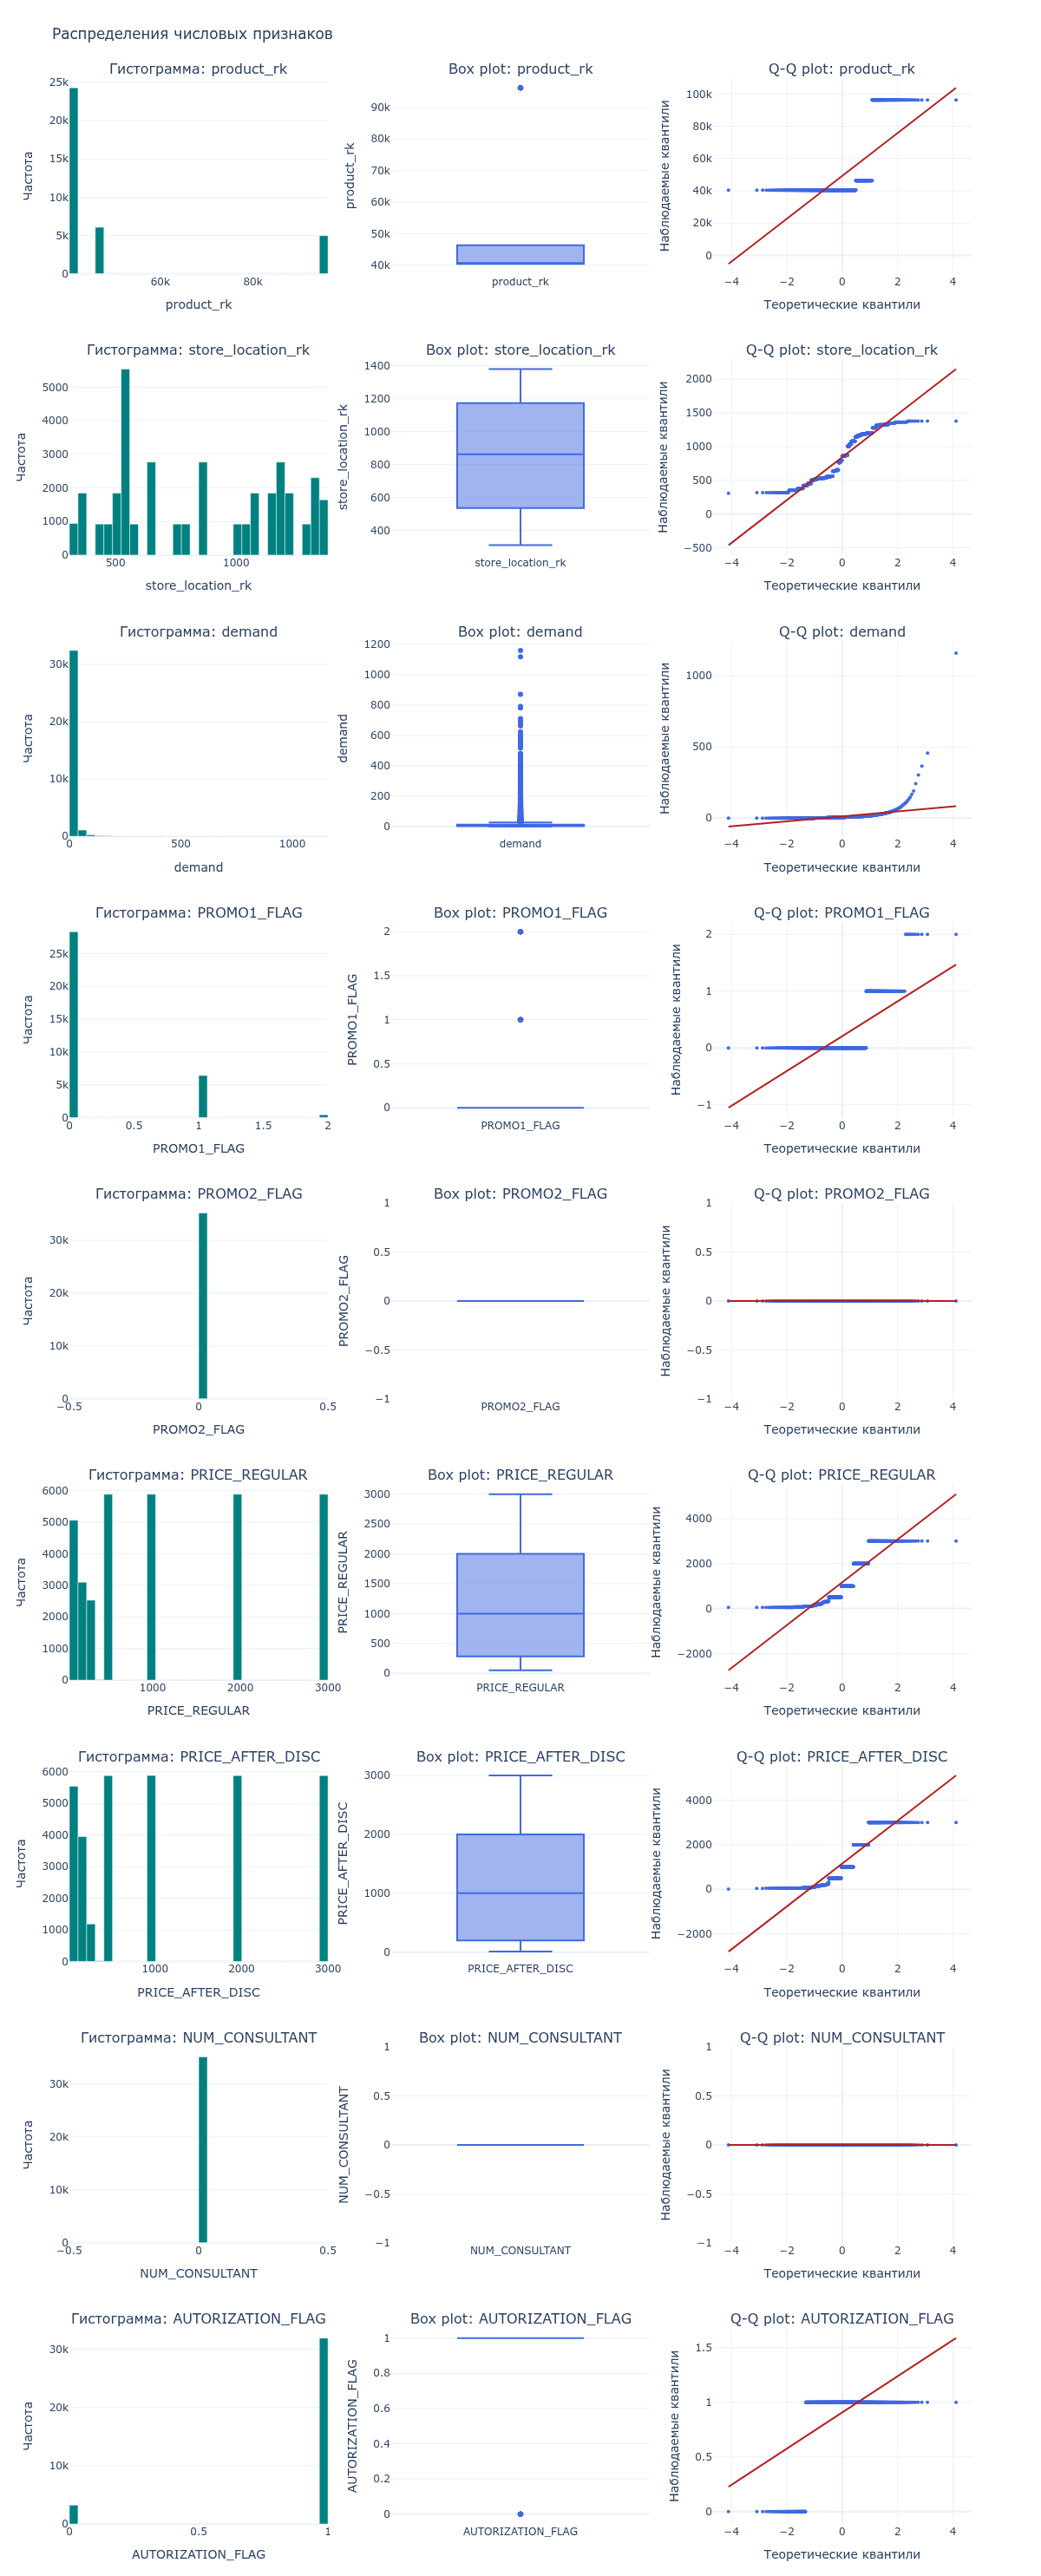

In [5]:
if len(numeric_cols) > 0:
    subplot_titles = [
        f'{chart}: {col}'
        for col in numeric_cols
        for chart in ['Гистограмма', 'Box plot', 'Q-Q plot']
    ]
    fig = make_subplots(
        rows=len(numeric_cols), cols=3, subplot_titles=subplot_titles,
        horizontal_spacing=0.07, vertical_spacing=0.035,
    )
    for row, col in enumerate(numeric_cols, start=1):
        values = train[col].dropna().to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        if not len(values):
            continue

        # Передаём готовые бины, чтобы не хранить в ipynb копию всех значений.
        counts, edges = np.histogram(values, bins=30)
        fig.add_trace(go.Bar(
            x=(edges[:-1] + edges[1:]) / 2, y=counts, width=np.diff(edges),
            marker_color='teal', name=col,
            hovertemplate='Значение: %{x:.4g}<br>Частота: %{y}<extra></extra>',
        ), row=row, col=1)
        fig.add_trace(go.Box(
            y=values, name=col, boxpoints='outliers', marker_color='royalblue',
        ), row=row, col=2)

        if len(values) >= 2:
            (theoretical, ordered), (slope, intercept, _) = stats.probplot(values, dist='norm')
            # Регрессия использует все наблюдения; для экрана достаточно 1000 точек.
            indices = np.unique(np.linspace(0, len(values) - 1, min(len(values), 1000), dtype=int))
            fig.add_trace(go.Scatter(
                x=theoretical[indices], y=ordered[indices], mode='markers',
                marker=dict(size=4, color='royalblue'), name=f'Q-Q: {col}',
            ), row=row, col=3)
            line_x = np.array([theoretical[0], theoretical[-1]])
            fig.add_trace(go.Scatter(
                x=line_x, y=slope * line_x + intercept, mode='lines',
                line=dict(color='firebrick'), name='Линия регрессии',
            ), row=row, col=3)

        fig.update_xaxes(title_text=col, row=row, col=1)
        fig.update_yaxes(title_text='Частота', row=row, col=1)
        fig.update_yaxes(title_text=col, row=row, col=2)
        fig.update_xaxes(title_text='Теоретические квантили', row=row, col=3)
        fig.update_yaxes(title_text='Наблюдаемые квантили', row=row, col=3)

    fig.update_layout(
        title='Распределения числовых признаков', height=330 * len(numeric_cols),
        width=1200, showlegend=False, margin=dict(t=90, b=60), bargap=0.05,
    )
    fig.show()

# Анализ Пропущеных значений

,Пропуски в train,% от train,Пропуски в test,% от test
AUTORIZATION_FLAG,185.0,0.52,NaN,NaN
NUM_CONSULTANT,185.0,0.52,NaN,NaN
PRICE_AFTER_DISC,1132.0,3.20,NaN,NaN
PRICE_REGULAR,1127.0,3.19,NaN,NaN
PROMO1_FLAG,185.0,0.52,NaN,NaN
PROMO2_FLAG,185.0,0.52,NaN,NaN
demand,1200.0,3.40,1404.0,100.0


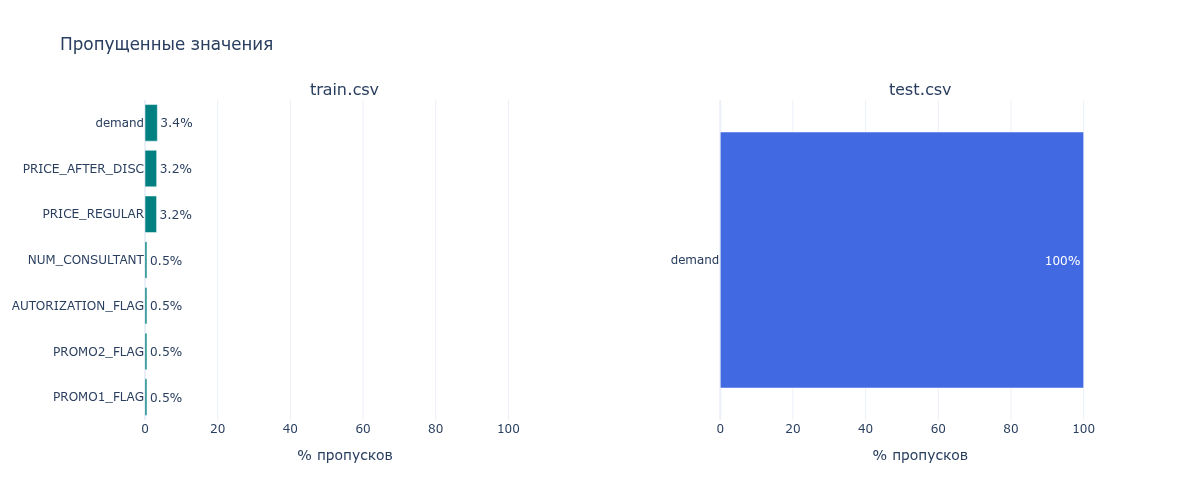

In [6]:
missing_train = train.isnull().sum()
missing_test = test.isnull().sum()

missing_summary = pd.DataFrame({
    'Пропуски в train': missing_train,
    '% от train': (missing_train / len(train) * 100).round(2),
    'Пропуски в test': missing_test,
    '% от test': (missing_test / len(test) * 100).round(2),
})
display(missing_summary[
    (missing_summary['Пропуски в train'] > 0) | (missing_summary['Пропуски в test'] > 0)
])

if missing_train.sum() > 0 or missing_test.sum() > 0:
    fig = make_subplots(rows=1, cols=2, subplot_titles=['train.csv', 'test.csv'], horizontal_spacing=0.18)
    for column, (missing, frame, color) in enumerate([
        (missing_train, train, 'teal'), (missing_test, test, 'royalblue'),
    ], start=1):
        percentages = (missing[missing > 0] / len(frame) * 100).sort_values()
        fig.add_trace(go.Bar(
            x=percentages.values, y=percentages.index, orientation='h',
            marker_color=color, text=percentages.round(1), texttemplate='%{text}%',
            hovertemplate='%{y}: %{x:.1f}%<extra></extra>',
        ), row=1, col=column)
        fig.update_xaxes(title_text='% пропусков', range=[0, 110], row=1, col=column)
        fig.update_yaxes(automargin=True, row=1, col=column)
    fig.update_layout(title='Пропущенные значения', height=500, width=1200, showlegend=False)
    fig.show()

# Сравнение Тест и Трейн

In [7]:
print("Столбцы train:", list(train.columns))
print("Столбцы test:", list(test.columns))

common_cols = set(train.columns) & set(test.columns)
print(f"\nОбщие столбцы: {len(common_cols)}")
print(f"Уникальные в train: {set(train.columns) - set(test.columns)}")
print(f"Уникальные в test: {set(test.columns) - set(train.columns)}")

Столбцы train: ['product_rk', 'store_location_rk', 'period_start_dt', 'demand', 'PROMO1_FLAG', 'PROMO2_FLAG', 'PRICE_REGULAR', 'PRICE_AFTER_DISC', 'NUM_CONSULTANT', 'AUTORIZATION_FLAG']
Столбцы test: ['id', 'product_rk', 'store_location_rk', 'period_start_dt', 'demand']

Общие столбцы: 4
Уникальные в train: {'NUM_CONSULTANT', 'PRICE_AFTER_DISC', 'PRICE_REGULAR', 'PROMO2_FLAG', 'AUTORIZATION_FLAG', 'PROMO1_FLAG'}
Уникальные в test: {'id'}


# **Глобальная фильтрация по времени работы магазинов**

In [8]:
def parse_store_date(date_str):
    if pd.isna(date_str):
        return pd.NaT
    value = datetime.datetime.strptime(str(date_str).split(':')[0], '%d%b%Y')
    # 01Jan5999 в справочнике означает, что дата закрытия ещё не назначена.
    # Ограничиваем дату для совместимости с datetime64[ns] в pandas 2.x.
    return pd.Timestamp(min(value, pd.Timestamp.max.normalize().to_pydatetime()))

def filter_open_stores(sales, locations):
    store_dates = locations[['STORE_LOCATION_RK', 'STORE_OPEN_DTTM', 'STORE_CLOSURE_DTTM']].copy()
    store_dates['open_dt'] = store_dates['STORE_OPEN_DTTM'].map(parse_store_date)
    store_dates['close_dt'] = store_dates['STORE_CLOSURE_DTTM'].map(parse_store_date)
    merged = sales.merge(
        store_dates[['STORE_LOCATION_RK', 'open_dt', 'close_dt']],
        left_on='store_location_rk', right_on='STORE_LOCATION_RK',
        how='left', validate='many_to_one', indicator=True,
    )
    if merged['_merge'].ne('both').any() or merged['open_dt'].isna().any():
        raise ValueError("Не найдена дата открытия одного из магазинов")
    active = (
        (merged['period_start_dt'] >= merged['open_dt'])
        & (merged['close_dt'].isna() | (merged['period_start_dt'] <= merged['close_dt']))
    )
    return merged.loc[active].drop(columns=['STORE_LOCATION_RK', 'open_dt', 'close_dt', '_merge']).copy()

ts_retail = filter_open_stores(train, store_location)
print(f"Удалено {len(train) - len(ts_retail)} строк вне периода работы магазинов.")
if ts_retail.empty:
    raise ValueError("После фильтрации магазинов не осталось данных")

Удалено 13023 строк вне периода работы магазинов.


## 1. Generate Segments for each Attributes

### 1.1. Demand Volume segmentation

После расчёта групп показаны по три реальных временных ряда каждого типа.
Тип определяется рассчитанной меткой, а не внешним видом графика.
Один ряд может иллюстрировать разные признаки; пропуски не заменяются нулями.

In [9]:
# Продолжаем с отфильтрованными данными; повторная загрузка train отменяла фильтр.
ts_id_columns = ['store_location_rk', 'product_rk']
ts_retail = ts_retail.sort_values(ts_id_columns + ['period_start_dt']).reset_index(drop=True)
ts_retail.head()

series_example_records = []

def show_series_examples(data, labels, group_column, group_titles, n_examples=3):
    """По 3 реальных ряда на тип; пропущенные недели остаются пропусками."""
    keys = ['store_location_rk', 'product_rk']
    observed = data.dropna(subset=['demand'])
    coverage = observed.groupby(keys).agg(n_observations=('demand', 'size'), mean_demand=('demand', 'mean'), positive_observations=('demand', lambda values: values.gt(0).sum())).reset_index()
    classified = coverage.merge(labels[keys + [group_column]], on=keys, validate='one_to_one')
    for group_value, title in group_titles.items():
        candidates = classified.loc[classified[group_column] == group_value]
        # Для наглядности предпочитаем историю от 12 недель с ненулевым спросом.
        preferred = candidates.loc[(candidates['n_observations'] >= 12) & (candidates['mean_demand'] > 0)]
        if group_column in ['has_trend', 'has_seasonality']:
            informative = preferred.loc[preferred['positive_observations'] >= 12]
            if len(informative) >= n_examples:
                preferred = informative
        if len(preferred) >= n_examples:
            candidates = preferred
        candidates = candidates.sort_values(['mean_demand'] + keys).reset_index(drop=True)
        count = min(n_examples, len(candidates))
        if count == 0:
            print(f'{title}: в данных нет рядов этого типа.')
            continue
        # Берём разные уровни спроса внутри типа; выбор полностью воспроизводим.
        selected = candidates.iloc[np.linspace(0, len(candidates) - 1, count, dtype=int)]
        series_list, titles = [], []
        for _, pair in selected.iterrows():
            store, product = int(pair['store_location_rk']), int(pair['product_rk'])
            series = observed.loc[
                (observed['store_location_rk'] == store) & (observed['product_rk'] == product)
            ].sort_values('period_start_dt').set_index('period_start_dt')['demand']
            zero_share = series.eq(0).mean()
            titles.append(f'Магазин {store} · товар {product} · недель: {len(series)} · нулевых: {zero_share:.0%}')
            series_list.append(series.reindex(pd.date_range(series.index.min(), series.index.max(), freq='7D')))
            series_example_records.append({
                'attribute': group_column, 'group': group_value, 'type': title,
                'store_location_rk': store, 'product_rk': product,
                'n_observations': len(series), 'zero_share': zero_share,
            })
        fig = make_subplots(rows=count, cols=1, shared_xaxes=True, subplot_titles=titles, vertical_spacing=0.12)
        for row, series in enumerate(series_list, start=1):
            fig.add_trace(go.Scatter(
                x=series.index, y=series.values, mode='lines+markers', connectgaps=False,
                name='Спрос', legendgroup='demand', showlegend=row == 1,
                line=dict(color='teal'), marker=dict(size=4),
                hovertemplate='Неделя: %{x|%d.%m.%Y}<br>Спрос: %{y:.2f}<extra></extra>',
            ), row=row, col=1)
            zeros = series.loc[series.eq(0)]
            fig.add_trace(go.Scatter(
                x=zeros.index, y=zeros.values, mode='markers',
                name='Нулевой спрос', legendgroup='zeros', showlegend=row == 1,
                marker=dict(color='firebrick', size=6),
                hovertemplate='Неделя: %{x|%d.%m.%Y}<br>Спрос: 0<extra></extra>',
            ), row=row, col=1)
            if group_column == 'has_trend':
                known = series.dropna()
                x = np.arange(len(known))
                fitted = linregress(x, known.values)
                fig.add_trace(go.Scatter(
                    x=known.index, y=fitted.intercept + fitted.slope * x, mode='lines',
                    name='Линейный тренд', legendgroup='trend', showlegend=row == 1,
                    line=dict(color='orange', dash='dash'),
                ), row=row, col=1)
            fig.update_yaxes(title_text='Спрос', rangemode='tozero', row=row, col=1)
        fig.update_xaxes(title_text='Неделя', row=count, col=1)
        fig.update_layout(
            title=f'{title} — {count} примера', height=280 * count + 100, width=1200,
            legend=dict(orientation='h', y=-0.12, yanchor='top'), margin=dict(t=100, b=130),
            meta={'example_attribute': group_column, 'example_group': str(group_value), 'example_count': count},
        )
        fig.show()

In [10]:
def abc_analysis(values, return_idx=True, a_share=0.80, b_share=0.95,
                 plot=True, title="ABC analysis"):
    """
    ABC-анализ по вкладу в суммарный объем.
    Возвращает индексы элементов A/B/C и строит график
    """

    x = np.asarray(values, dtype=float)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    n = len(x)
    if n == 0:
        res = {'A': np.array([], dtype=int), 'B': np.array([], dtype=int), 'C': np.array([], dtype=int)}
        res.update({'Aind': res['A'], 'Bind': res['B'], 'Cind': res['C']})
        return res

    order = np.argsort(-x)            # по убыванию
    sorted_x = x[order]
    total = sorted_x.sum()

    if total <= 0:
        res = {'A': np.array([], dtype=int), 'B': np.array([], dtype=int), 'C': np.arange(n, dtype=int)}
        res.update({'Aind': res['A'], 'Bind': res['B'], 'Cind': res['C']})
        return res

    cum_share = np.cumsum(sorted_x) / total
    frac_data = np.arange(1, n + 1) / n

    # границы по доле вклада (80% и 95% по умолчанию)
    i_ab = int(np.searchsorted(cum_share, a_share, side='left'))   # индекс границы A|B
    i_bc = int(np.searchsorted(cum_share, b_share, side='left'))   # индекс границы B|C

    # маски сегментов
    a_mask = np.zeros(n, dtype=bool); a_mask[:i_ab + 1] = True
    b_mask = np.zeros(n, dtype=bool); b_mask[i_ab + 1:i_bc + 1] = True
    c_mask = np.zeros(n, dtype=bool); c_mask[i_bc + 1:] = True

    A = order[a_mask]
    B = order[b_mask]
    C = order[c_mask]

    # Визуализация той же ABC-кривой и тех же границ средствами Plotly.
    if plot:
        xA, yA = frac_data[i_ab], cum_share[i_ab]
        xB, yB = frac_data[i_bc], cum_share[i_bc]
        fig = go.Figure([
            go.Scatter(x=frac_data, y=cum_share, mode='lines', name='data', line=dict(color='green')),
            go.Scatter(x=[0, 1], y=[0, 1], mode='lines', name='identity', line=dict(color='royalblue', dash='dash')),
            go.Scatter(x=[0, 1], y=[1, 0], mode='lines', name='uniform', line=dict(color='gray', dash='dash')),
            go.Scatter(x=[xA, xB], y=[yA, yB], mode='markers', name='Границы ABC', marker=dict(color='firebrick', size=10)),
        ])
        for x, y, label in [(xA, yA, 'A|B'), (xB, yB, 'B|C')]:
            fig.add_vline(x=x, line_color='firebrick')
            fig.add_hline(y=y, line_color='firebrick', line_dash='dot')
            fig.add_annotation(x=x, y=y, text=label, showarrow=True, ay=-30)
        for left, right, label, count, color in [
            (0, xA, 'A', len(A), 'teal'),
            (xA, xB, 'B', len(B), 'orange'),
            (xB, 1, 'C', len(C), 'gray'),
        ]:
            fig.add_vrect(x0=left, x1=right, fillcolor=color, opacity=0.08, line_width=0)
            fig.add_annotation(x=(left + right) / 2, y=0.12, text=f'{label}<br>n={count}', showarrow=False)
        fig.update_layout(
            title=title, height=600, width=1000,
            xaxis=dict(title='Доля рядов', range=[0, 1], tickformat='.0%'),
            yaxis=dict(title='Накопленная доля суммы', range=[0, 1.02], tickformat='.0%'),
            legend=dict(orientation='h', y=-0.18),
        )
        fig.show()

    res = {'A': A, 'B': B, 'C': C}
    # алиасы
    res.update({'Aind': A, 'Bind': B, 'Cind': C})
    return res


In [11]:
ts_id_columns = ['store_location_rk', 'product_rk']


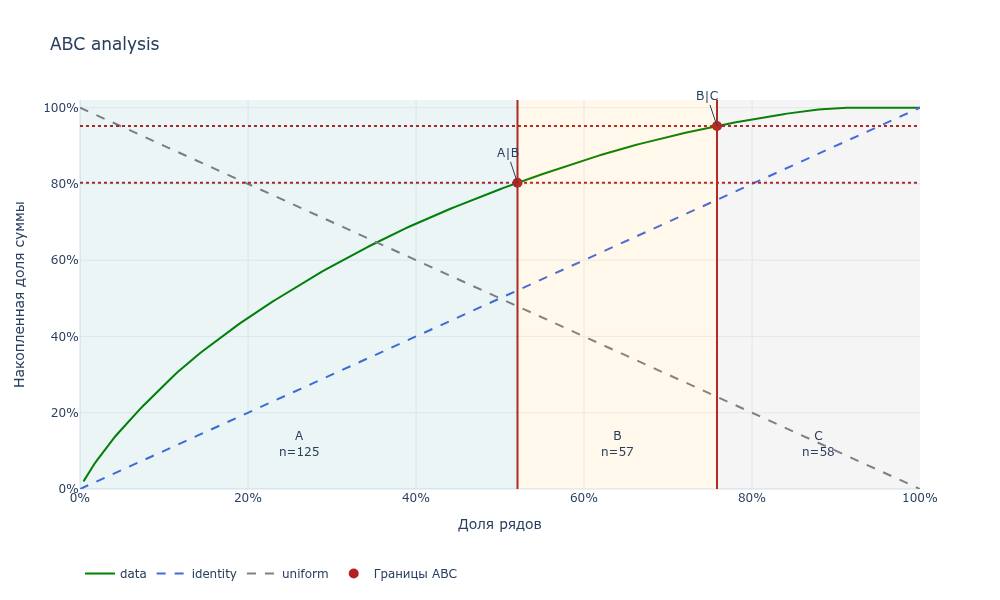

,store_location_rk,product_rk,demand_volume,volume_group
0,317,40369,784.207532,A
1,317,40370,1130.868306,A
2,317,40372,519.934426,B
3,317,40373,327.928962,C
4,317,46272,356.820290,C


In [12]:
# 1) объем спроса по паре store-product
ts_volume_values = ts_retail.groupby(ts_id_columns)['demand'].sum()

# 2) ABC-анализ (индексы A/B/C)
ts_volume_abc = abc_analysis(ts_volume_values.fillna(0).values, True)

# 3) таблица сегментов + метки
volume = ts_volume_values.reset_index(name='demand_volume')
volume['volume_group'] = 'C'
volume.loc[ts_volume_abc['A'], 'volume_group'] = 'A'
volume.loc[ts_volume_abc['B'], 'volume_group'] = 'B'

volume.head()


In [13]:
ts_retail = ts_retail.merge(
    volume[ts_id_columns + ['demand_volume', 'volume_group']],
    on=ts_id_columns,
    how='left'
)

ts_retail.head()


,product_rk,store_location_rk,period_start_dt,demand,PROMO1_FLAG,PROMO2_FLAG,PRICE_REGULAR,PRICE_AFTER_DISC,NUM_CONSULTANT,AUTORIZATION_FLAG,demand_volume,volume_group
0,40369,317,2018-03-19,6.0,0.0,0.0,500.0,500.0,0.0,1.0,784.207532,A
1,40369,317,2018-03-26,2.0,0.0,0.0,500.0,500.0,0.0,1.0,784.207532,A
2,40369,317,2018-04-02,2.0,0.0,0.0,500.0,500.0,0.0,1.0,784.207532,A
3,40369,317,2018-04-09,4.0,0.0,0.0,500.0,500.0,0.0,1.0,784.207532,A
4,40369,317,2018-04-16,3.0,0.0,0.0,500.0,500.0,0.0,1.0,784.207532,A


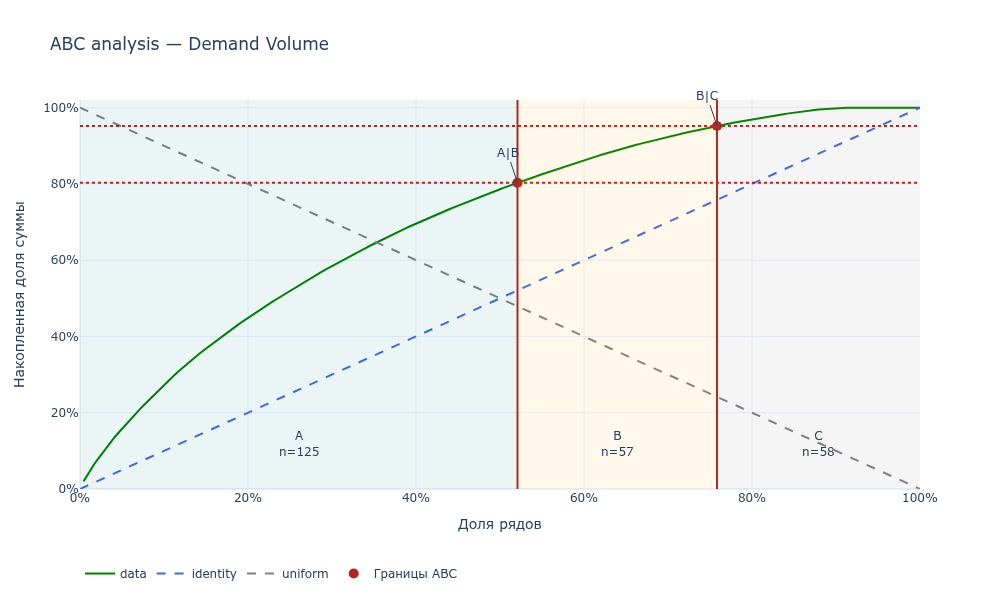

,store_location_rk,product_rk,demand_volume,volume_group
0,317,40369,784.207532,A
1,317,40370,1130.868306,A
2,317,40372,519.934426,B
3,317,40373,327.928962,C
4,317,46272,356.820290,C


volume_group
A    125
C     58
B     57
Name: count, dtype: int64


In [14]:
# 1.1

ts_id_columns = ['store_location_rk', 'product_rk']

# считаем объем спроса по каждой паре товар–магазин
volume = (
    ts_retail
    .groupby(ts_id_columns)['demand']
    .sum()
    .reset_index(name='demand_volume')
)

# ABC-анализ + график (рисует abc_analysis)
abc_vol = abc_analysis(
    volume['demand_volume'].fillna(0).values,
    True,
    plot=True,
    title="ABC analysis — Demand Volume"
)

# присваиваем группы A/B/C
volume['volume_group'] = 'C'
volume.loc[abc_vol['A'], 'volume_group'] = 'A'
volume.loc[abc_vol['B'], 'volume_group'] = 'B'

# присоединяем группы к исходным данным
# --- SAFE MERGE: 1.1 Demand Volume ---

# 1) Удаляем старые версии колонок (если они есть)
ts_retail = ts_retail.drop(
    columns=['demand_volume', 'volume_group'],
    errors='ignore'
)

# 2) Присоединяем ТОЛЬКО нужные колонки
ts_retail = ts_retail.merge(
    volume[['store_location_rk', 'product_rk',
               'demand_volume', 'volume_group']],
    on=['store_location_rk', 'product_rk'],
    how='left'
)

display(volume.head())
print(volume['volume_group'].value_counts())


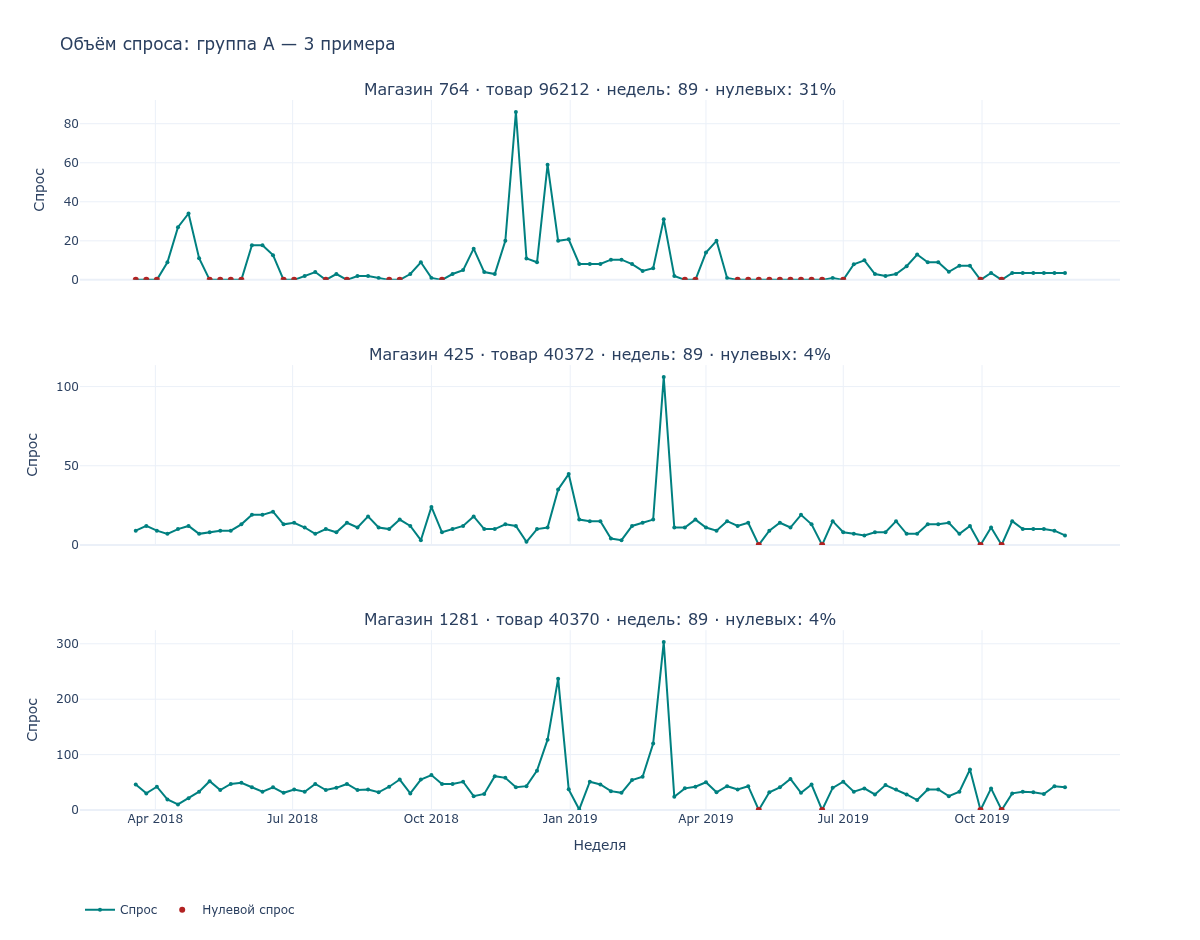

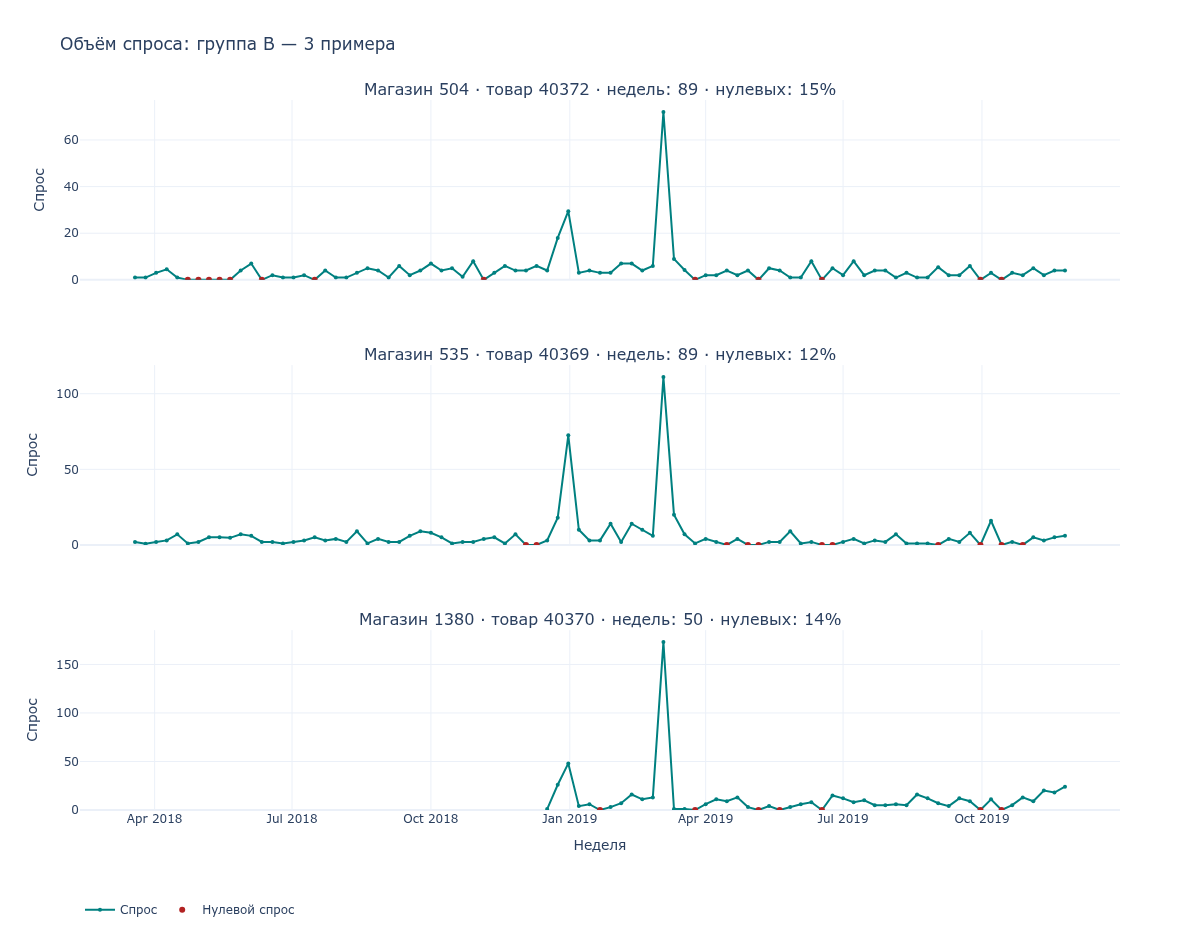

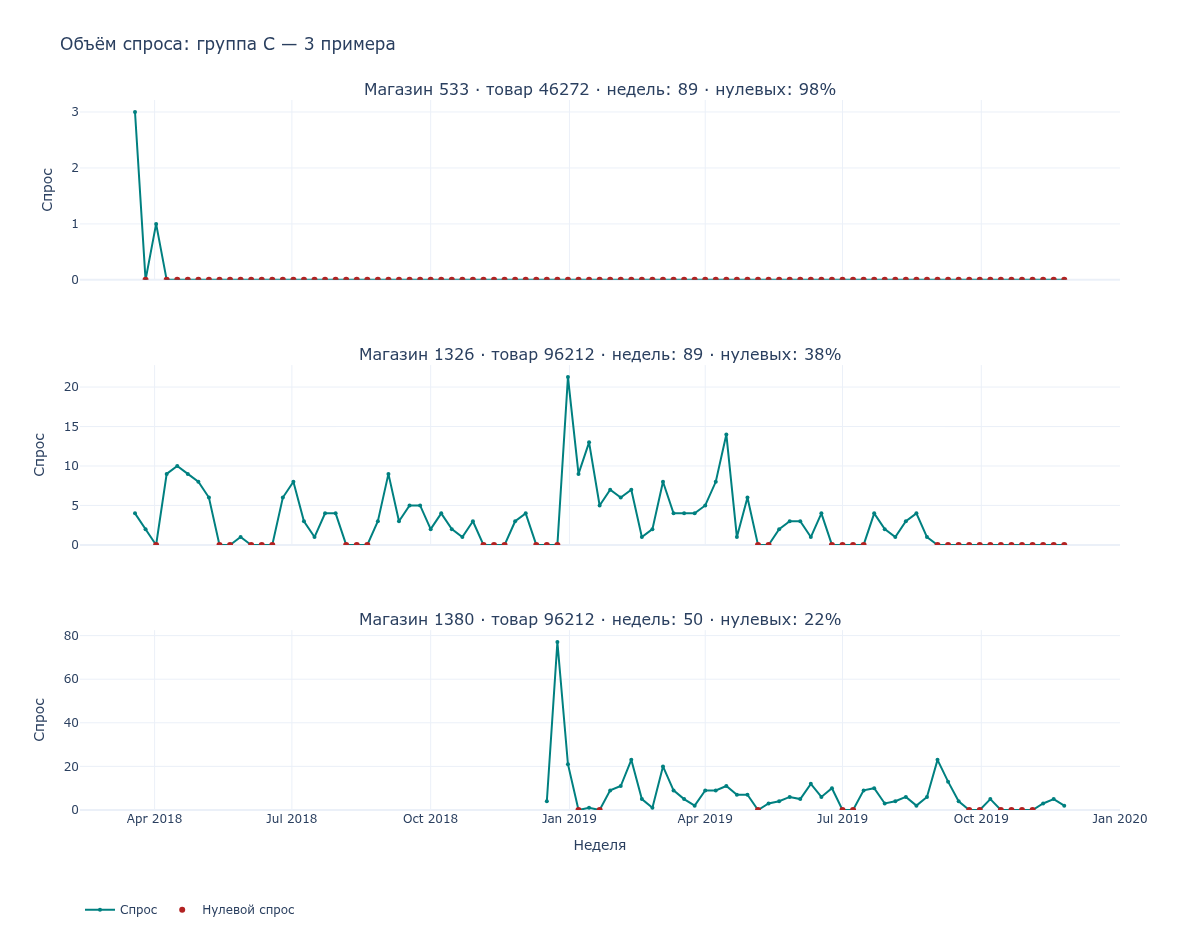

In [15]:
show_series_examples(ts_retail, volume, 'volume_group', {
    'A': 'Объём спроса: группа A', 'B': 'Объём спроса: группа B', 'C': 'Объём спроса: группа C',
})

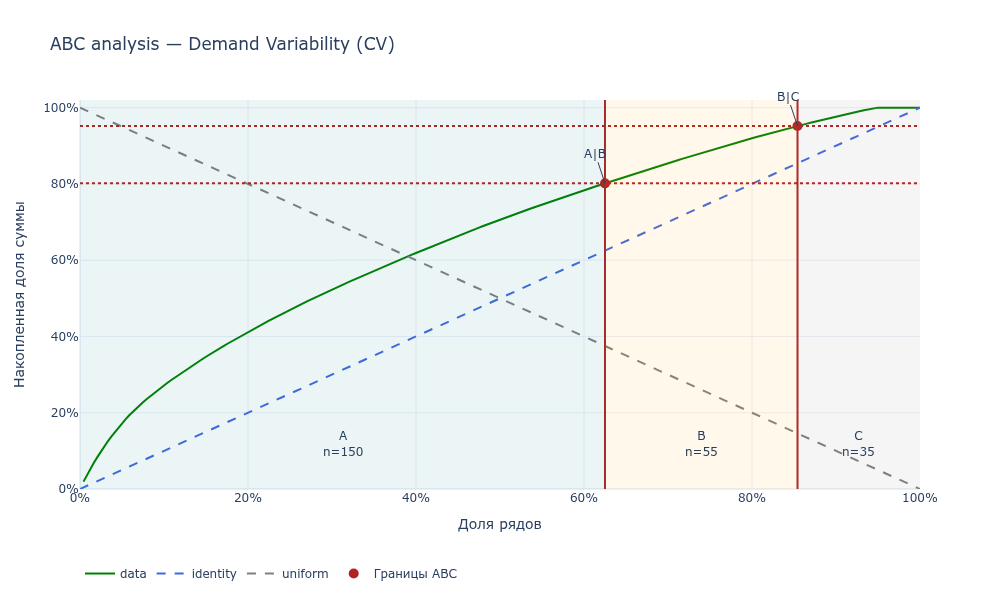

,store_location_rk,product_rk,demand_cv,variability_group
0,317,40369,2.579563,A
1,317,40370,1.760849,A
2,317,40372,1.508990,A
3,317,40373,1.595548,A
4,317,46272,1.121352,B


variability_group
A    150
B     55
C     35
Name: count, dtype: int64


In [16]:
# 1.2

g = ts_retail.groupby(ts_id_columns)['demand']

mean_d = g.mean()
std_d  = g.std(ddof=0)

ts_cv_values = (std_d / mean_d.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0)

# ABC-анализ + график
abc_var = abc_analysis(
    ts_cv_values.values,
    True,
    plot=True,
    title="ABC analysis — Demand Variability (CV)"
)

demand_var = ts_cv_values.reset_index(name='demand_cv')

# присваиваем группы A/B/C
demand_var['variability_group'] = 'C'
demand_var.loc[abc_var['A'], 'variability_group'] = 'A'
demand_var.loc[abc_var['B'], 'variability_group'] = 'B'


# присоединяем к исходным данным
ts_retail = ts_retail.merge(
    demand_var[ts_id_columns + ['demand_cv', 'variability_group']],
    on=ts_id_columns,
    how='left'
)

display(demand_var.head())
print(demand_var['variability_group'].value_counts())


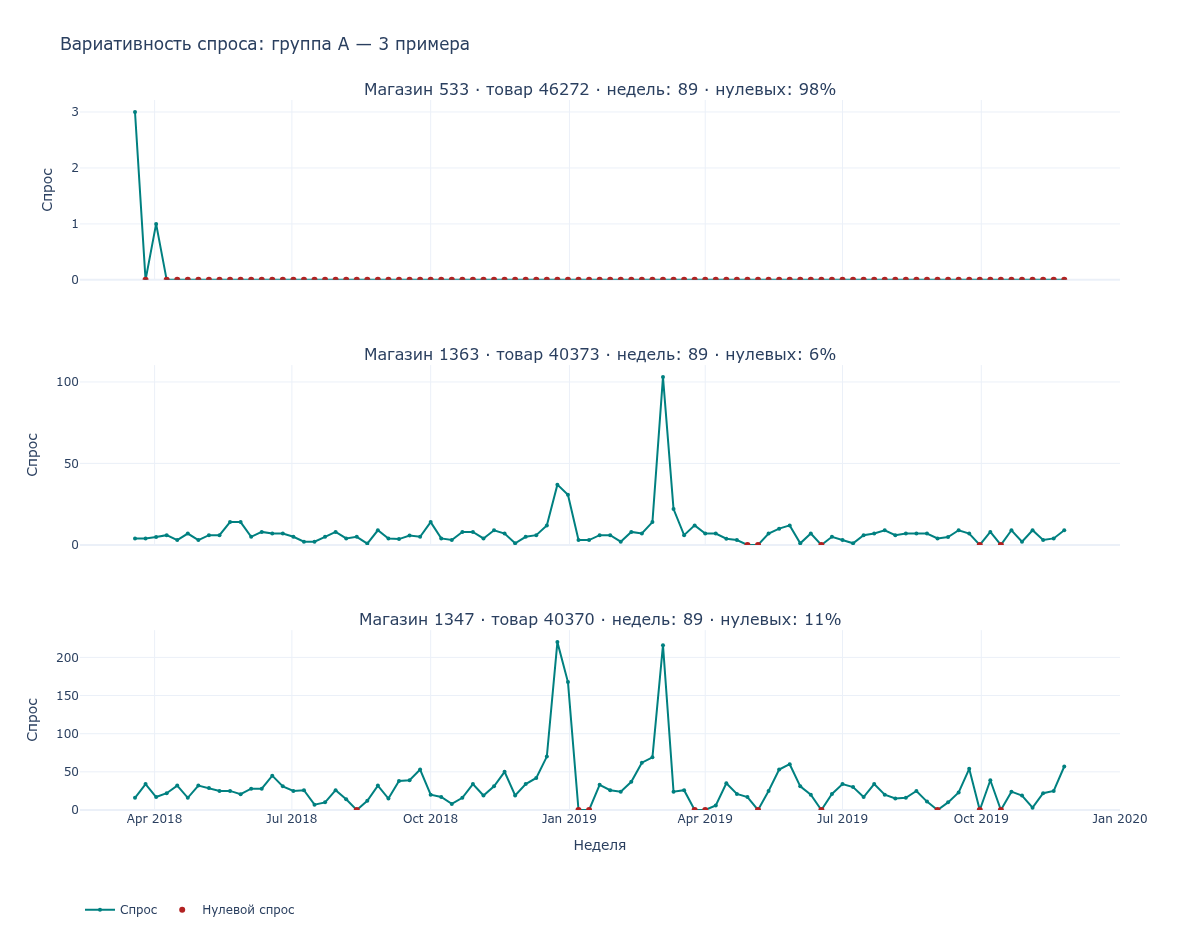

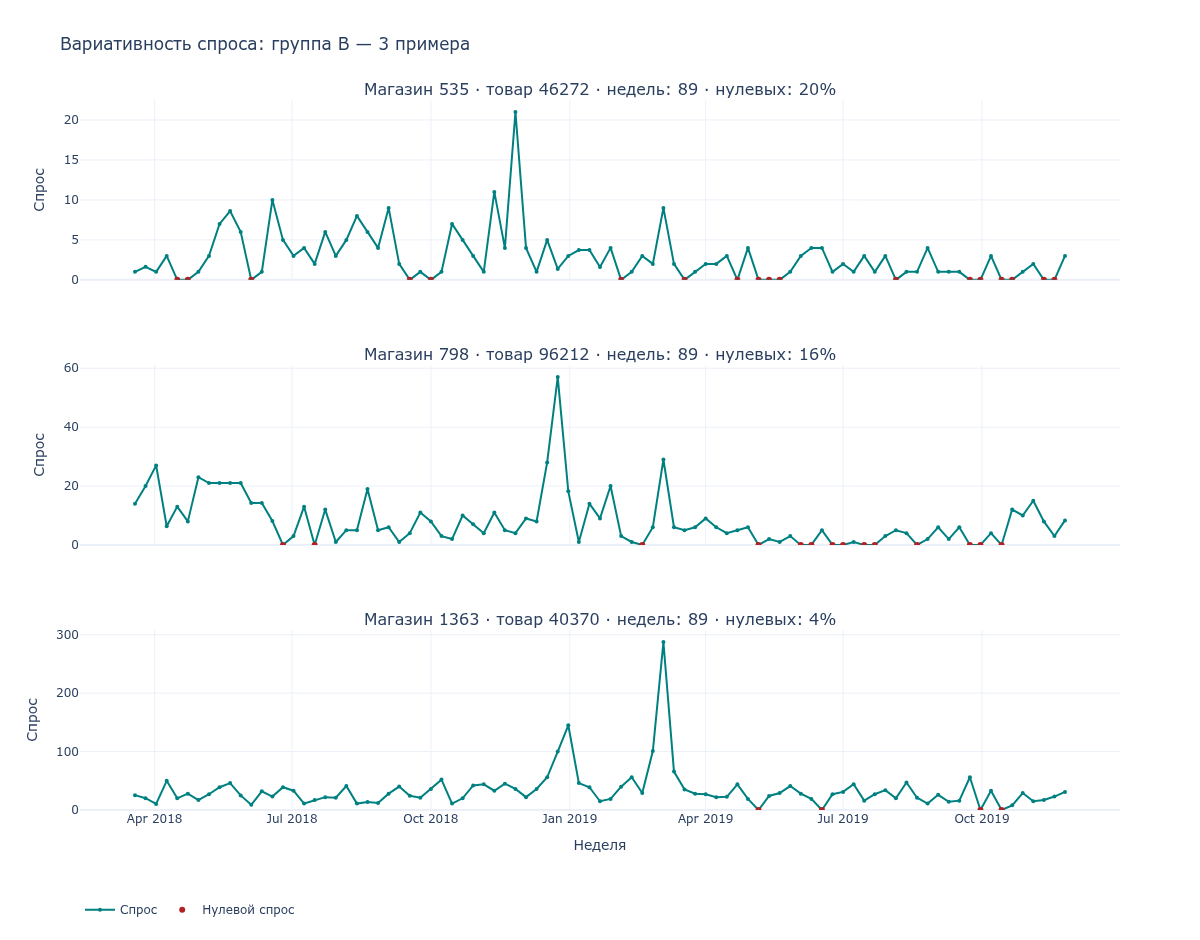

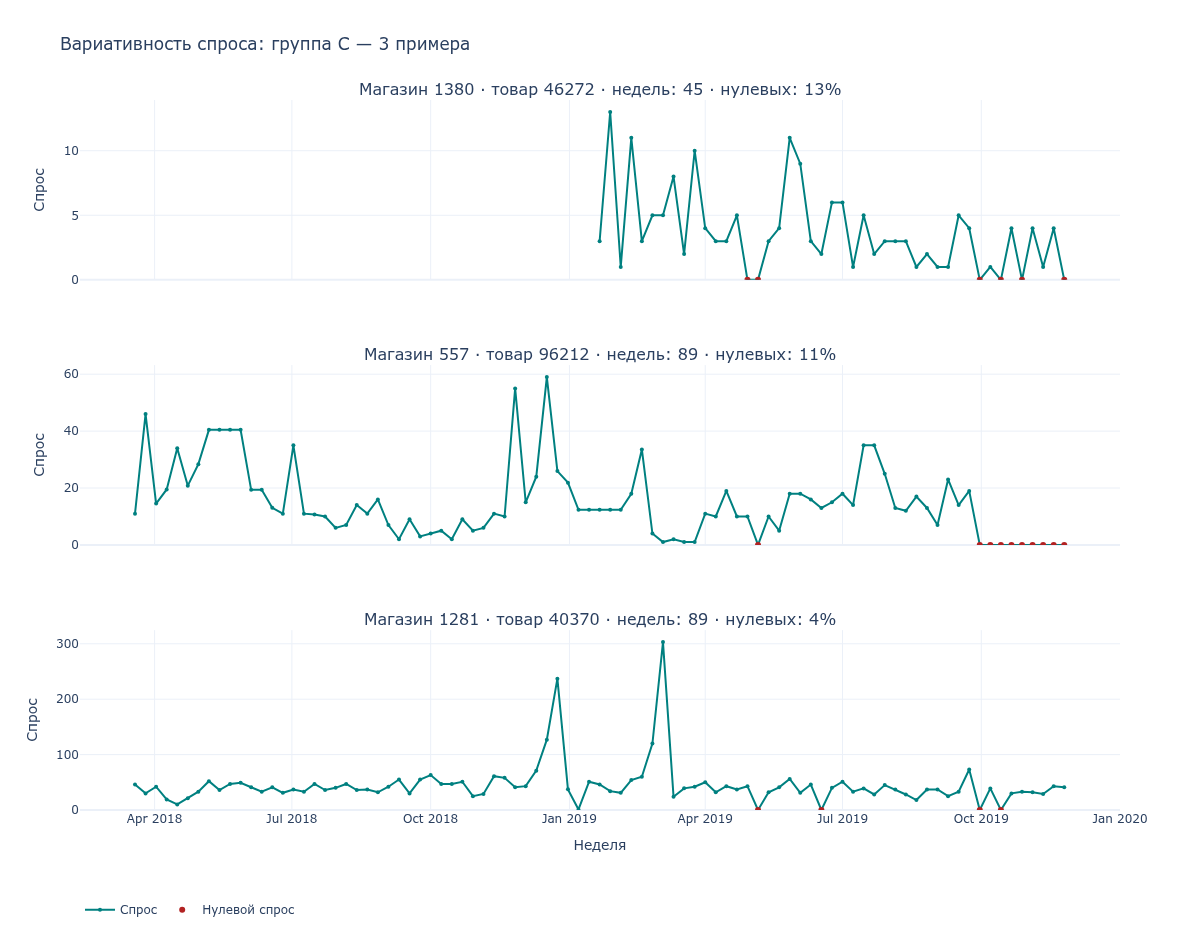

In [17]:
show_series_examples(ts_retail, demand_var, 'variability_group', {
    'A': 'Вариативность спроса: группа A', 'B': 'Вариативность спроса: группа B', 'C': 'Вариативность спроса: группа C',
})

# **1.3. Признак Seasonality (0/1)**


Признак Seasonality определяет, содержит ли временной ряд сезонную компоненту по эвристике автокорреляции.
Поскольку в исходном датасете отсутствуют календарные признаки (например, день недели),
сезонность определяется только по самой динамике спроса.

Результат:

* 1 — сезонность присутствует

* 0 — сезонности нет или недостаточно данных

1) Получение временного ряда по SKU × Store

    Извлекает временной ряд спроса для конкретного товара и магазина.
    
    Зачем нужна функция:
    - Оригинальный датафрейм содержит данные для всех товаров и магазинов
    - Нам нужно изолировать данные для конкретной пары (product_rk, store_rk)
    - Функция фильтрует, сортирует по дате и преобразует в временной ряд
    
    Параметры:
    df : pd.DataFrame
        Исходный датафрейм с колонками product_rk, store_location_rk, period_start_dt, demand
    product_rk : int
        Идентификатор товара (SKU)
    store_rk : int
        Идентификатор магазина
    
    Возвращает:
    pd.Series
        Временной ряд спроса с датами в качестве индекса

In [18]:
def get_ts(df: pd.DataFrame, product_rk: int, store_rk: int) -> pd.Series:
    mask = (df['product_rk'] == product_rk) & (df['store_location_rk'] == store_rk)
    filtered_df = df[mask]
    filtered_df = filtered_df.sort_values('period_start_dt')
    ts = filtered_df.set_index('period_start_dt')['demand'].astype(float)

    return ts

2) Оценка сезонного периода (lag)

    Определяет наиболее вероятный сезонный период (лаг) временного ряда.
    
    Зачем нужна функция:
    - Сезонность означает повторяющиеся паттерны с фиксированным интервалом
    - Нужно найти этот интервал (например, неделя, месяц, год)
    - Используется автокорреляционная функция (ACF) для поиска периодов
    
    Алгоритм:
    1. Вычисляем автокорреляцию ряда
    2. Находим пики в автокорреляционной функции
    3. Выбираем лаг с максимальной автокорреляцией как сезонный период
    
    Параметры:
    ts : np.ndarray
        Временной ряд (массив значений спроса)
    
    Возвращает:
    int
        Предполагаемый сезонный период (лаг).
        Возвращает 1 если данных недостаточно или сезонность не найдена.
    """

In [19]:
def find_seasonality_period(ts: np.ndarray) -> int:


    ts = np.asarray(ts, dtype=float)
    ts_clean = ts[np.isfinite(ts)]
    if len(ts_clean) < 3:
        return 1
    ts_normalized = ts_clean - ts_clean.mean()
    acf_full = np.correlate(ts_normalized, ts_normalized, 'full')
    acf = acf_full[-len(ts_normalized):]
    first_diff = np.diff(acf)
    second_diff = np.diff(np.sign(first_diff))
    peaks = (second_diff < 0).nonzero()[0] + 1
    if len(peaks) == 0:
        return 1
    best_peak_idx = np.argmax(acf[peaks])
    seasonal_period = int(peaks[best_peak_idx])

    return seasonal_period

3) Тест на сезонность

Сезонность считается присутствующей, если:

* длина ряда значительно превышает сезонный лаг

* автокорреляция на сезонном лаге достаточно высокая

    Проверяет, имеет ли временной ряд сезонную компоненту по порогу автокорреляции.
    
    Зачем нужна функция:
    - Определяет, нужно ли учитывать сезонность при прогнозировании
    - Помогает выбрать правильную модель (с сезонностью или без)
    
    Критерии сезонности:
    1. Ряд должен быть достаточно длинным (min_series_length)
    2. Длина ряда должна значительно превышать сезонный период (min_excess_length)
    3. Автокорреляция на сезонном лаге должна быть высокой (correlation_threshold)
    
    Параметры:
    ts : np.ndarray
        Временной ряд
    min_series_length : int
        Минимальная длина ряда для анализа (по умолчанию 5)
    min_excess_length : int
        На сколько должна превышать длина ряда сезонный период (по умолчанию 10)
    correlation_threshold : float
        Порог для нормированной автокорреляции (по умолчанию 0.25)
    
    Возвращает:
    int
        1 - сезонность присутствует
        0 - сезонности нет или недостаточно данных

In [20]:
def has_seasonality(ts: np.ndarray,
                    min_series_length: int = 5,
                    min_excess_length: int = 10,
                    correlation_threshold: float = 0.25) -> int:
    ts = np.asarray(ts, dtype=float)
    ts_clean = ts[np.isfinite(ts)]
    if len(ts_clean) < min_series_length:
        print(f"  Слишком короткий ряд ({len(ts_clean)} < {min_series_length}) → сезонность 0")
        return 0
    seasonal_period = find_seasonality_period(ts_clean)
    if seasonal_period <= 1 or np.ptp(ts_clean) == 0:
        return 0
    if len(ts_clean) <= seasonal_period + min_excess_length:
        print(f"  Ряд слишком короткий для периода {seasonal_period} "
              f"({len(ts_clean)} ≤ {seasonal_period} + {min_excess_length}) → сезонность 0")
        return 0
    ts_normalized = ts_clean - ts_clean.mean()
    acf_full = np.correlate(ts_normalized, ts_normalized, 'full')
    acf = acf_full[-len(ts_normalized):]
    acf_norm = acf / acf[0]
    acf_at_seasonal_lag = acf_norm[seasonal_period]
    has_seasonality_flag = int(acf_at_seasonal_lag > correlation_threshold)
    print(f"  Длина ряда: {len(ts_clean)}, Сезонный период: {seasonal_period}, "
          f"ACF(период): {acf_at_seasonal_lag:.3f}, "
          f"Порог: {correlation_threshold}, Сезонность: {has_seasonality_flag}")

    return has_seasonality_flag

4) Создание датафрейма с флагами сезонности для всех SKU × Store

    Создает датафрейм с флагами сезонности для всех уникальных пар SKU × Store.
    
    Зачем нужна функция:
    - Оригинальный train_df не содержит признака сезонности
    - Нужно вычислить сезонность для каждой комбинации товар-магазин
    - Результат можно использовать как признак в модели или для анализа
    
    Параметры:
    train_df : pd.DataFrame
        Обучающий датафрейм
    
    Возвращает:
    pd.DataFrame
        Датафрейм с колонками: product_rk, store_location_rk, has_seasonality

In [21]:
def create_seasonality_dataframe(train_df: pd.DataFrame) -> pd.DataFrame:
    unique_pairs = train_df[['product_rk', 'store_location_rk']].drop_duplicates()
    print(f"Всего уникальных пар: {len(unique_pairs)}")
    seasonality_results = []
    for idx, (product_rk, store_rk) in enumerate(unique_pairs.itertuples(index=False), 1):
        ts_series = get_ts(train_df, product_rk, store_rk)
        ts_array = ts_series.values
        seasonal_flag = has_seasonality(ts_array)
        seasonality_results.append({
            'product_rk': product_rk,
            'store_location_rk': store_rk,
            'has_seasonality': seasonal_flag
        })

        if idx % 100 == 0:
            print(f"Обработано {idx}/{len(unique_pairs)} пар")

    seasonality_df = pd.DataFrame(seasonality_results)

    seasonal_count = seasonality_df['has_seasonality'].sum()
    print(f"\nСтатистика сезонности:")
    print(f"  Всего пар: {len(seasonality_df)}")
    print(f"  Сезонные (has_seasonality=1): {seasonal_count} ({seasonal_count/len(seasonality_df)*100:.1f}%)")
    print(f"  Несезонные (has_seasonality=0): {len(seasonality_df) - seasonal_count} ({(len(seasonality_df) - seasonal_count)/len(seasonality_df)*100:.1f}%)")

    return seasonality_df

### Примеры сезонных и несезонных рядов — по три графика каждого типа

Всего уникальных пар: 240
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.296, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 10, ACF(период): 0.244, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.259, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.377, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 14, ACF(период): 0.335, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 4, ACF(период): 0.280, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.403, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 10, ACF(период): 0.308, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 10, ACF(период): 0.327, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 10, ACF(период): 0.264, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 3, ACF(период): 0.415, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период:

  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.234, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 19, ACF(период): 0.246, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 76, ACF(период): 0.197, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 11, ACF(период): 0.372, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.162, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 11, ACF(период): 0.283, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.251, Порог: 0.25, Сезонность: 1
Обработано 100/240 пар
  Длина ряда: 89, Сезонный период: 14, ACF(период): 0.258, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 3, ACF(период): 0.338, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.325, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 10, ACF(период): 0.342, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 1

  Длина ряда: 89, Сезонный период: 38, ACF(период): 0.289, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 3, ACF(период): 0.483, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 4, ACF(период): 0.400, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 4, ACF(период): 0.454, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 3, ACF(период): 0.461, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 3, ACF(период): 0.287, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.259, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.244, Порог: 0.25, Сезонность: 0
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.272, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 9, ACF(период): 0.303, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 4, ACF(период): 0.254, Порог: 0.25, Сезонность: 1
  Длина ряда: 89, Сезонный период: 35, ACF(период): 0.153, Порог

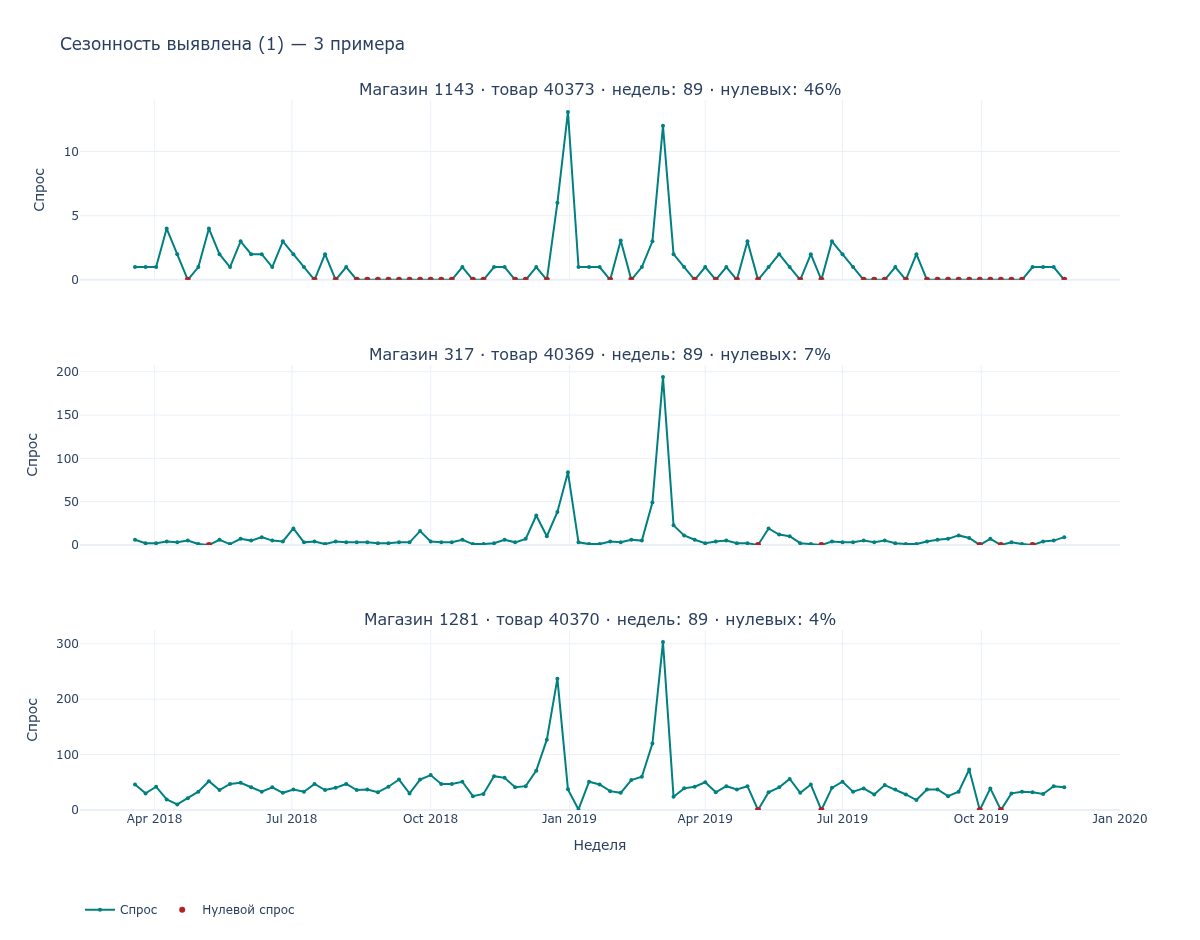

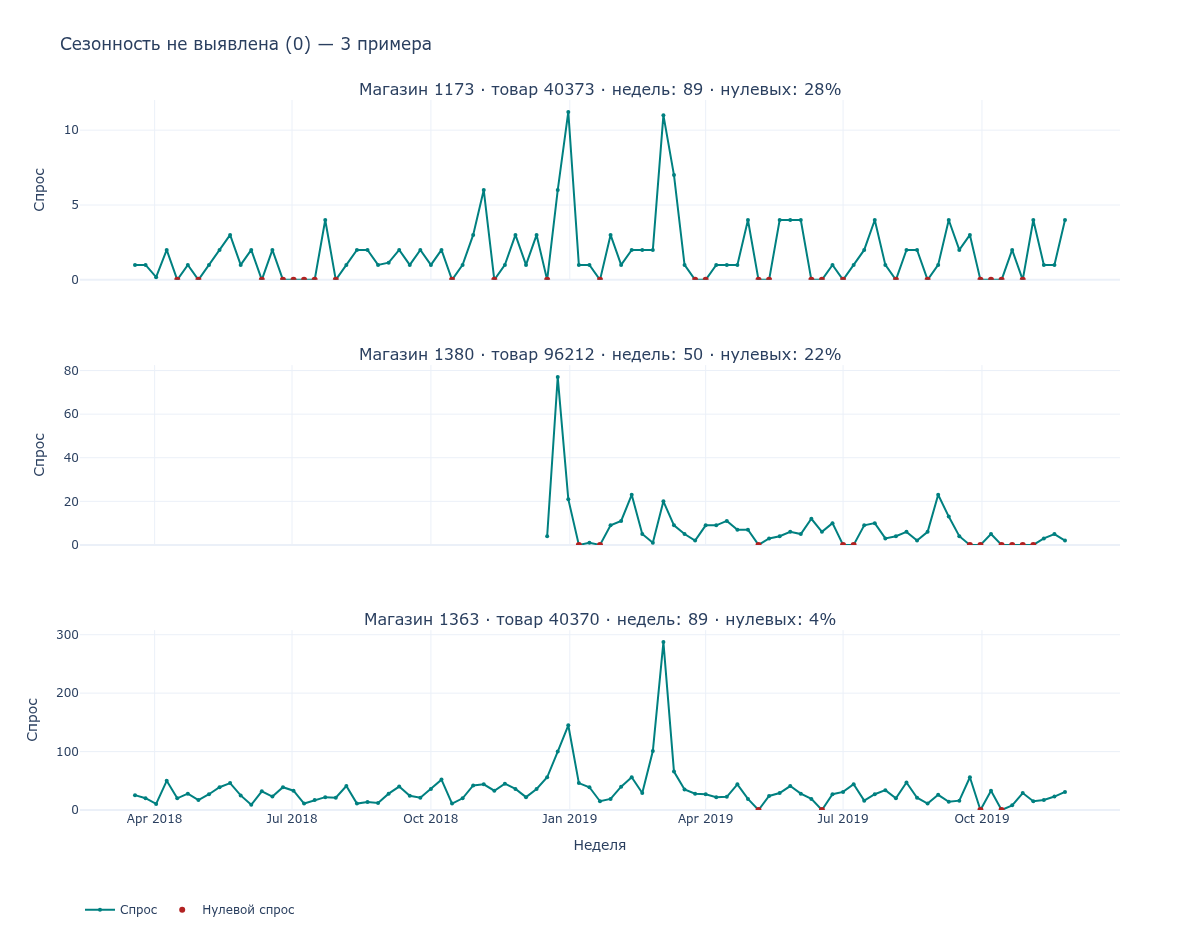

In [22]:
seas_df = create_seasonality_dataframe(ts_retail)
show_series_examples(ts_retail, seas_df, 'has_seasonality', {
    1: 'Сезонность выявлена (1)', 0: 'Сезонность не выявлена (0)',
})
example_pair = ts_retail[ts_id_columns].iloc[0]
test_ts = get_ts(ts_retail, example_pair['product_rk'], example_pair['store_location_rk'])

# **1.4. Trend segments (0/1)**

Признак Trend показывает, имеет ли временной ряд статистически значимую направленную динамику (рост/падение).
Тренд определяется с помощью линейной регрессии: если наклон значим по

p-value ≤ 0.05 → ряд трендовый.

Ниже приведены три ряда с флагом 1 и три с флагом 0. Оранжевая пунктирная
линия показывает линейную регрессию. Для наглядности при наличии выбора
предпочтение отдаётся рядам как минимум с 12 ненулевыми наблюдениями.


In [23]:
from scipy.stats import linregress
import numpy as np

def get_trend_flag(ts):
    ts = np.array(ts, dtype=float)
    ts = ts[~np.isnan(ts)]

    if len(ts) < 5 or np.ptp(ts) == 0:
        return 0
    x = np.arange(len(ts))
    res = linregress(x, ts)

    return int(res.pvalue <= 0.05)

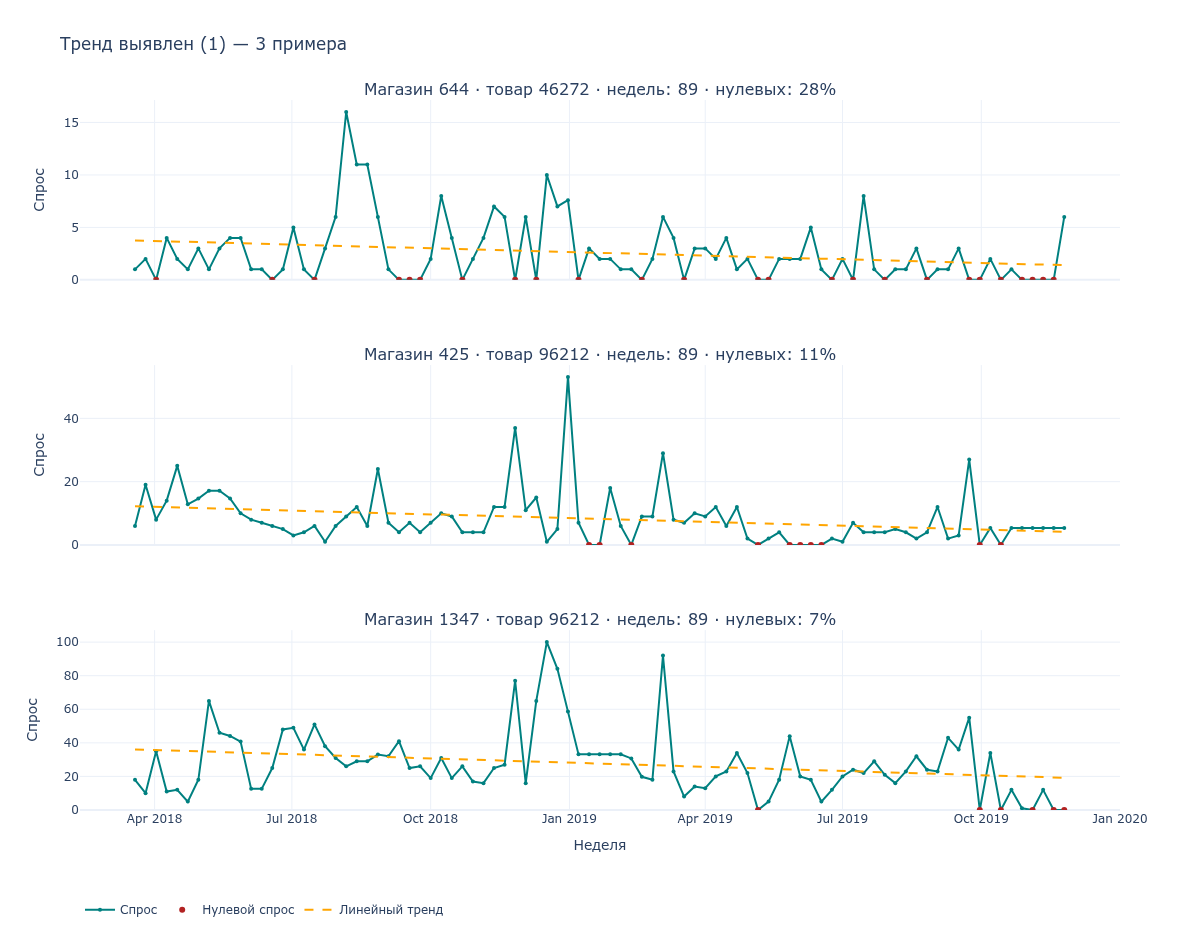

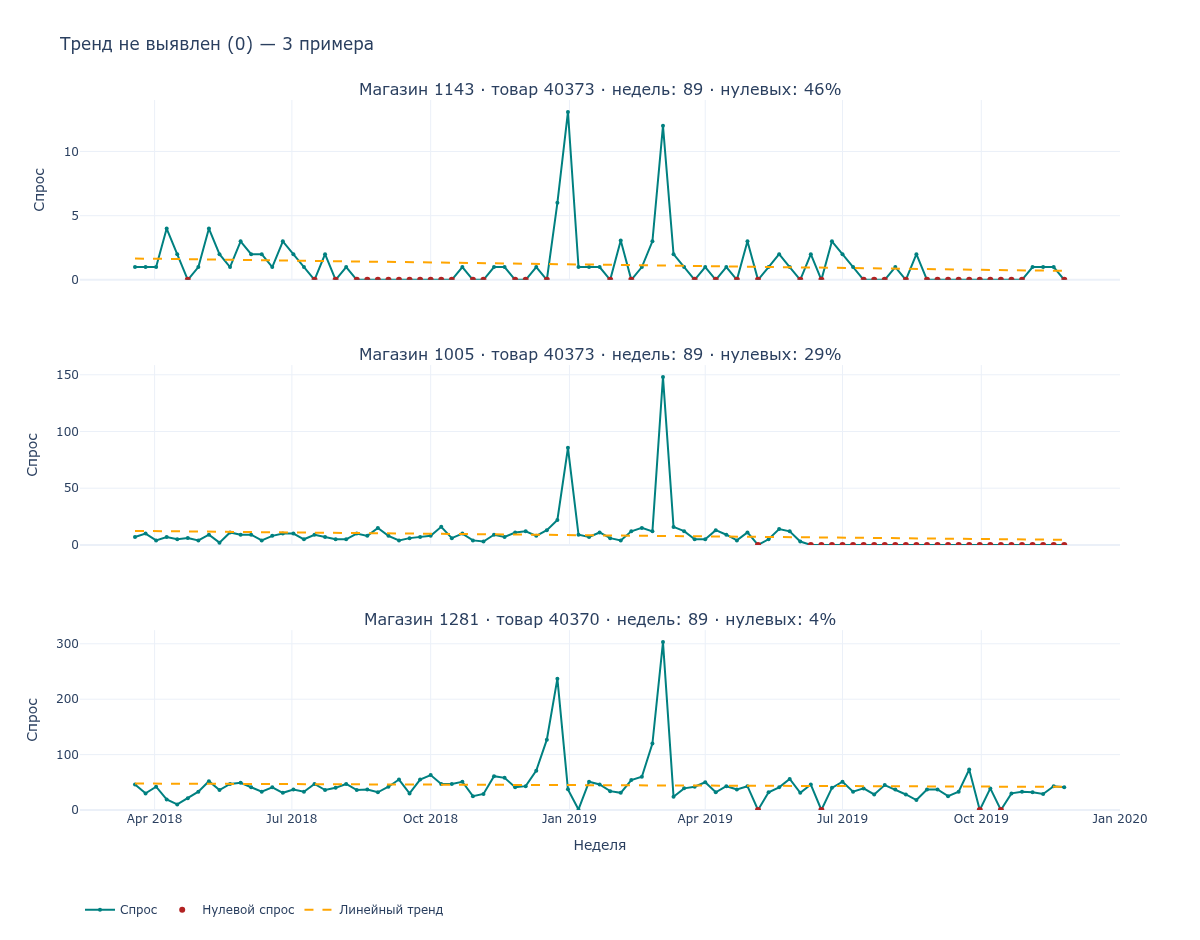

In [24]:
trend_results = []
for (store, product), group in ts_retail.groupby(ts_id_columns):
    trend_results.append({
        'product_rk': product, 'store_location_rk': store,
        'has_trend': get_trend_flag(group.sort_values('period_start_dt')['demand']),
    })
trend_df = pd.DataFrame(trend_results)
show_series_examples(ts_retail, trend_df, 'has_trend', {
    1: 'Тренд выявлен (1)', 0: 'Тренд не выявлен (0)',
})

# **1.5. Спорадичность (intermittency, 0/1)**

Спорадичность (intermittency) отражает нерегулярное появление ненулевого спроса.
Ниже приведены два критерия. Первый считает ряд спорадичным, если медианная длина
непрерывных ненулевых участков меньше 2. В итоговом индексе и при выборе примеров
используется второй критерий — тест таблицы сопряжённости.

In [25]:
from scipy.stats import chi2_contingency

In [26]:
def is_intermittent(ts):
    ts = np.array(ts, dtype=float)
    ts = ts[~np.isnan(ts)]

    if len(ts) < 3:
        return 0

    intervals = []
    cur = 0
    for val in ts:
        if val == 0:
            if cur > 0:
                intervals.append(cur)
            cur = 0
        else:
            cur += 1
    if cur > 0:
        intervals.append(cur)

    if len(intervals) == 0:
        return 0

    return int(np.median(intervals) < 2)

НОВАЯ ФУНКЦИЯ С CONTINGENCY TEST

Критерий спорадичности (intermittency) использует таблицу сопряжённости:
предыдущее состояние (0/1) × текущее состояние (0/1), где 1 означает ненулевой спрос.

- p-value > alpha → флаг спорадичности 1;
- p-value ≤ alpha, недостаточная длина или вырожденная таблица → флаг 0.

**Как читать примеры:** этот критерий не задаёт минимальную долю нулевых недель.
Поэтому флаг 1 может получить и ряд с частым спросом: в приведённых примерах
есть ряды лишь с 4–6% нулевых недель. Это метки текущего алгоритма, а не
утверждение, что каждый такой ряд имеет редкий спрос. Доля нулевых недель
указана над каждым графиком.


In [27]:
def is_intermittent_contingency(ts, alpha=0.05):
    ts = np.array(ts, dtype=float)
    ts = ts[~np.isnan(ts)]

    if len(ts) < 10:
        return 0
    contingency = np.zeros((2, 2), dtype=int)

    for i in range(1, len(ts)):
        prev = 1 if ts[i-1] > 0 else 0
        curr = 1 if ts[i] > 0 else 0
        contingency[prev, curr] += 1
    try:
        chi2, p_value, dof, expected = chi2_contingency(contingency)
    except ValueError:
        return 0

    return int(p_value > alpha)

ФУНКЦИЯ ДЛЯ РАЗМЕТКИ ВСЕХ ДАННЫХ

Создает DataFrame с флагами спорадичности для ВСЕХ пар (product_rk × store_location_rk)

In [28]:
def create_all_intermittency_flags(train_data):
    unique_pairs = train_data[['product_rk', 'store_location_rk']].drop_duplicates()

    results = []

    print(f"Обрабатываем {len(unique_pairs)} пар...")

    for idx, (product, store) in enumerate(unique_pairs.itertuples(index=False), 1):
        mask = (train_data['product_rk'] == product) & (train_data['store_location_rk'] == store)
        ts = train_data[mask].sort_values('period_start_dt')['demand'].astype(float).values
        flag = is_intermittent_contingency(ts)

        results.append({
            'product_rk': product,
            'store_location_rk': store,
            'is_intermittent': flag
        })

        if idx % 1000 == 0:
            print(f"  Обработано {idx}/{len(unique_pairs)}")
    flags_df = pd.DataFrame(results)
    print(f"\nРазметка создана!")
    print(f"Спорадичных рядов: {flags_df['is_intermittent'].mean():.1%}")

    return flags_df

### Примеры спорадичных и неспорадичных рядов — по три графика каждого типа

Обрабатываем 240 пар...



Разметка создана!
Спорадичных рядов: 71.7%


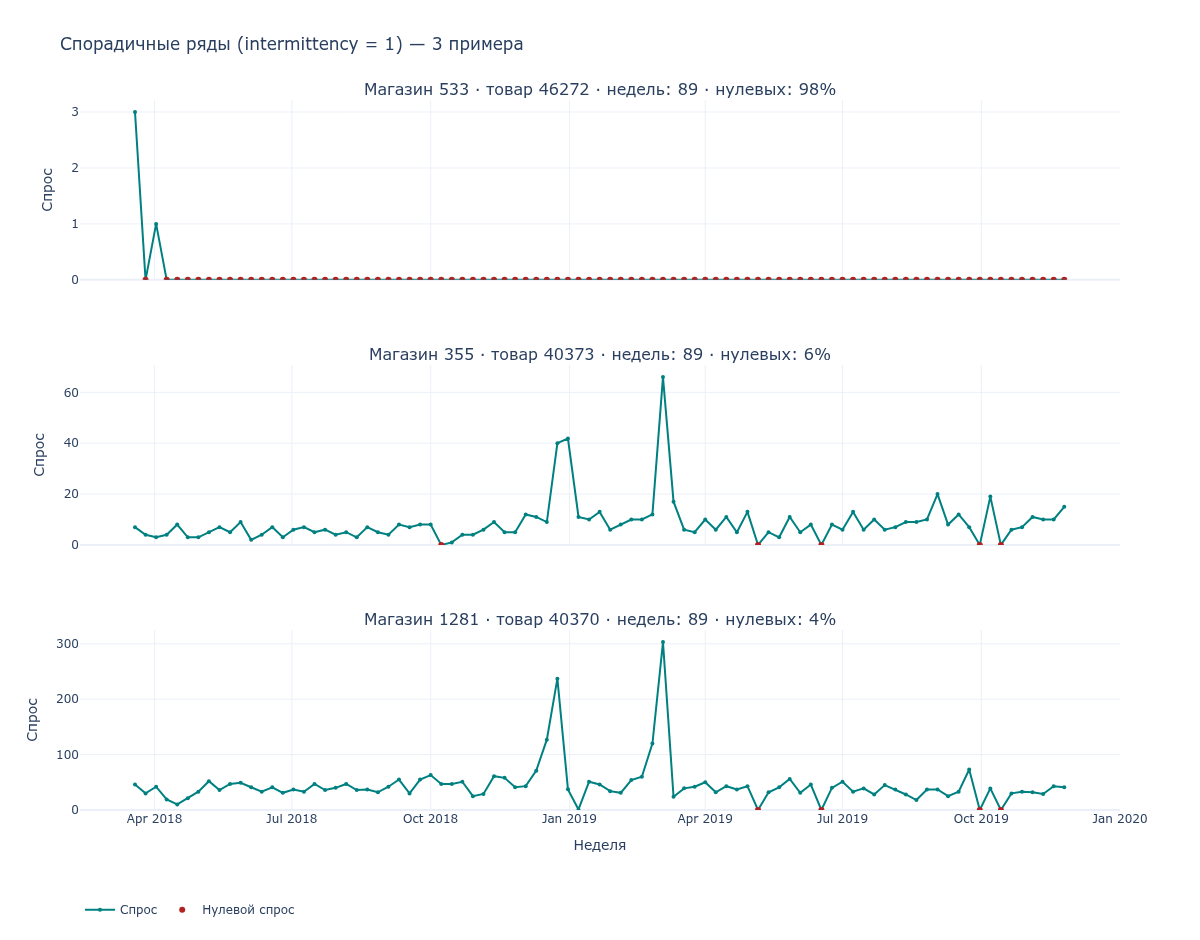

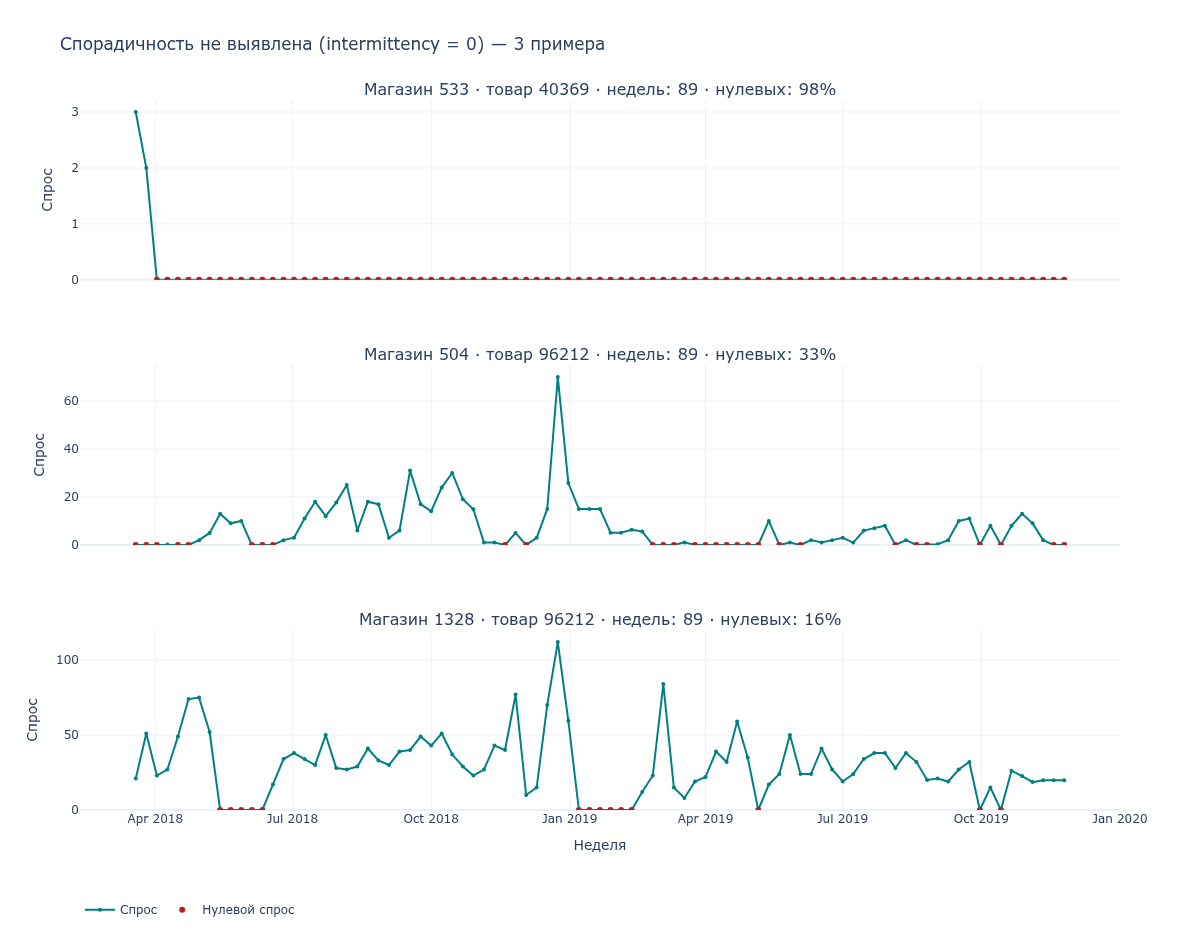

In [29]:
all_flags = create_all_intermittency_flags(ts_retail)
all_flags.to_csv(OUTPUT_DIR / 'intermittency_flags_all.csv', index=False)
train_with_flags = ts_retail.merge(all_flags, on=ts_id_columns, how='left', validate='many_to_one')
show_series_examples(ts_retail, all_flags, 'is_intermittent', {
    1: 'Спорадичные ряды (intermittency = 1)',
    0: 'Спорадичность не выявлена (intermittency = 0)',
})

# **PROMO DEPENDENCY SEGMENTATION**

Promo Dependency Segmentation - признак, показывающий, какая доля наблюдаемых недель товара приходится на промо-акции. Позволяет разделить товары на «органические» (стабильный спрос) и «промо-зависимые» (всплески продаж только во время акций).

Зачем это нужно: Высокая вариативность не всегда означает, что товар сложно прогнозировать.

Если вариативность вызвана промо-акциями, то товар легко прогнозируется,  достаточно знать календарь скидок.

Без учета промо такой товар ошибочно попадает в категорию «High Variability», занижая качество индекса.

Почему не используем в финальной группировке: Согласно условию задачи Forecastability Index должен строиться строго на основе 5 измерений. Добавление 6-го измерения (promo_group) нарушит формальные требования к размерности матрицы "5-dim cell". Поэтому данный расчет приводится справочно как потенциальная точка роста модели.

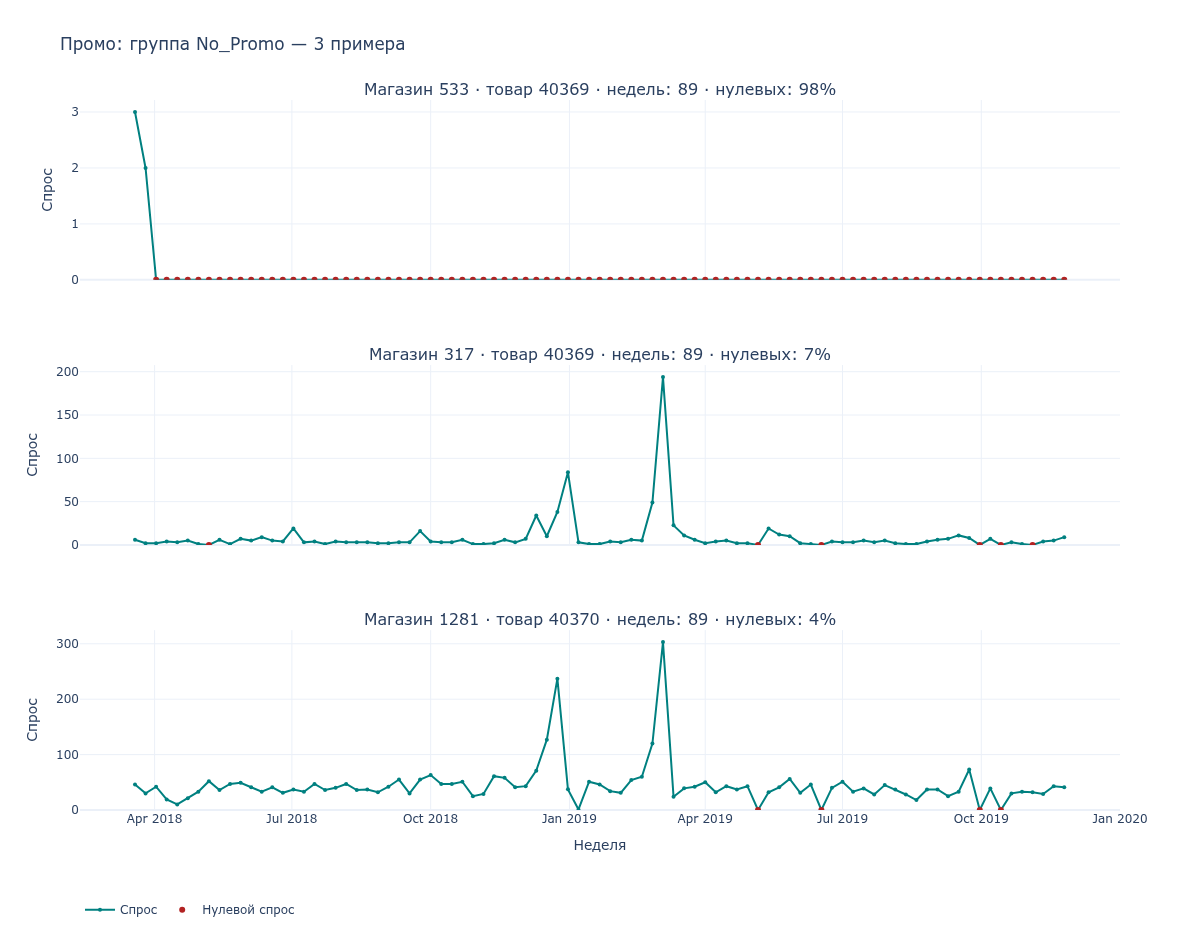

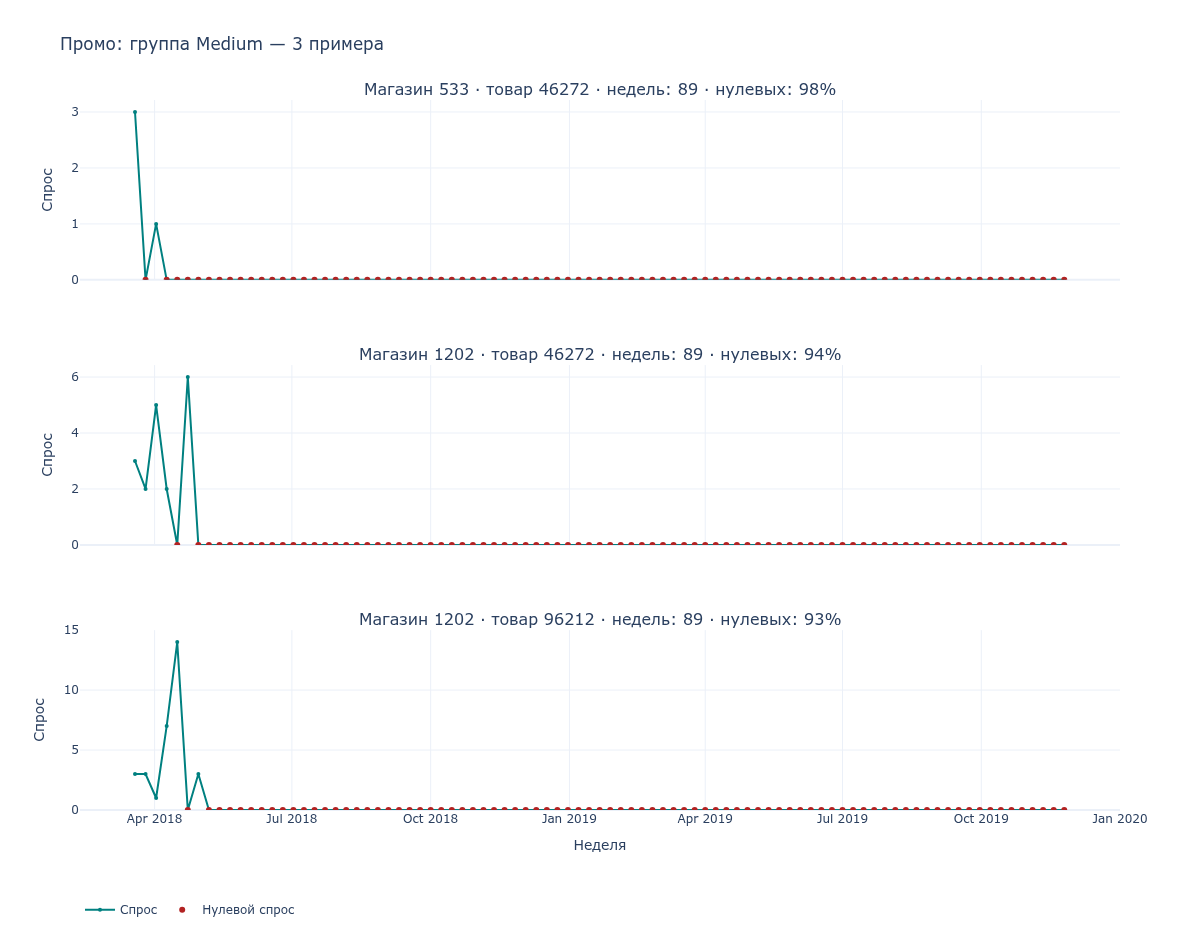

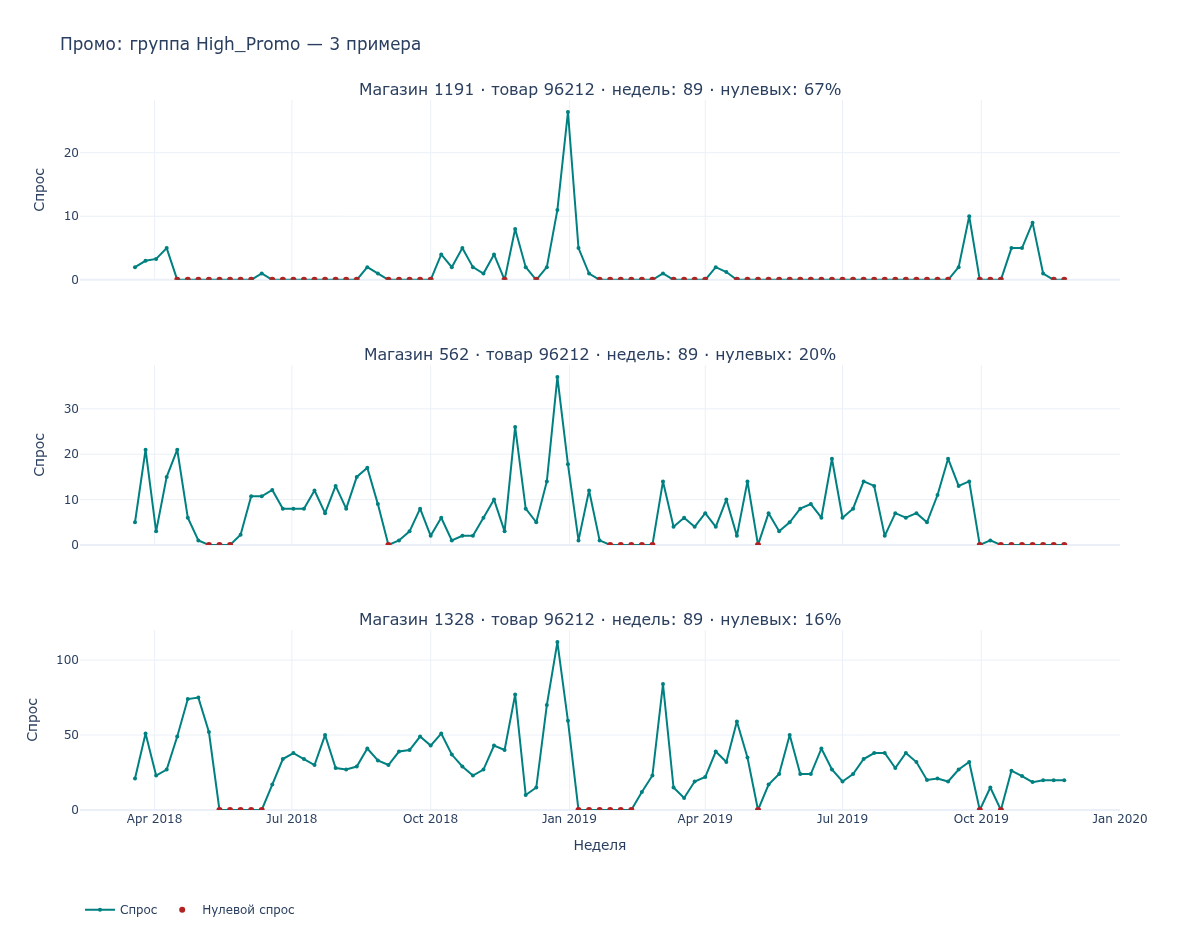

In [30]:
# Считаем долю недель с PROMO1_FLAG = 1 или PROMO2_FLAG = 1
ts_retail['is_promo'] = ((ts_retail['PROMO1_FLAG'] == 1) |
                         (ts_retail['PROMO2_FLAG'] == 1)).astype(int)

# Агрегируем по товарам
promo_stats = ts_retail.groupby(['store_location_rk', 'product_rk']).agg({
    'demand': 'sum',
    'is_promo': 'mean'
}).reset_index()

# Если более 30% времени товар в промо — считаем его промо-зависимым
promo_stats['promo_group'] = pd.cut(promo_stats['is_promo'],
                                    bins=[-0.1, 0.1, 0.3, 1.0],
                                    labels=['No_Promo', 'Medium', 'High_Promo'])

cols_drop = ['promo_group', 'is_promo']
ts_retail = ts_retail.drop(columns=[c for c in cols_drop if c in ts_retail.columns], errors='ignore')

ts_retail = ts_retail.merge(promo_stats[['store_location_rk', 'product_rk', 'promo_group']],
                            on=['store_location_rk', 'product_rk'],
                            how='left')

show_series_examples(ts_retail, promo_stats, 'promo_group', {
    'No_Promo': 'Промо: группа No_Promo', 'Medium': 'Промо: группа Medium', 'High_Promo': 'Промо: группа High_Promo',
})

## Step 2. Define benchmark forecastability for eash 5-dim cell from 1


## 2.1. Наивный прогноз (Naive Forecast)

используется как базовая модель (benchmark) для оценки прогнозируемости временных рядов.  
FI затем сравнивает фактическую ошибку (например, WAPE) этого простого прогноза для разных сегментов  
(Volume / Variability / Trend / Seasonality / Intermittency).

В проекте используется классический наивный подход:

Если временной ряд имеет вид:

$$
y_1, y_2, \ldots, y_T
$$

и последнее значение равно \( y_T \), то прогноз на горизонте \( h \) задаётся формулой:

$$
\hat{y}_{T+1} = \hat{y}_{T+2} = \ldots = \hat{y}_{T+h} = y_T
$$

То есть каждое прогнозное значение повторяет последнее наблюдение исторического ряда.


1. Горизонт прогноза

Горизонт берётся из числа уникальных дат в `test`: в приложенных данных это **6 недель**.
Фактический спрос в `test` отсутствует, поэтому WAPE оценивается на известных
исторических значениях `train` методом скользящего бэктеста.

In [31]:
forecast_horizon = test['period_start_dt'].nunique()
forecast_horizon


6

2. Наивный прогноз на заданный горизонт

Функция повторяет последнее известное значение спроса для всех будущих недель.

In [32]:
def naive_forecast(ts, horizon=4):

    ts = np.array(ts, dtype=float)
    ts = ts[~np.isnan(ts)]

    if len(ts) == 0:
        return np.zeros(horizon)

    last_value = ts[-1]
    return np.repeat(last_value, horizon)

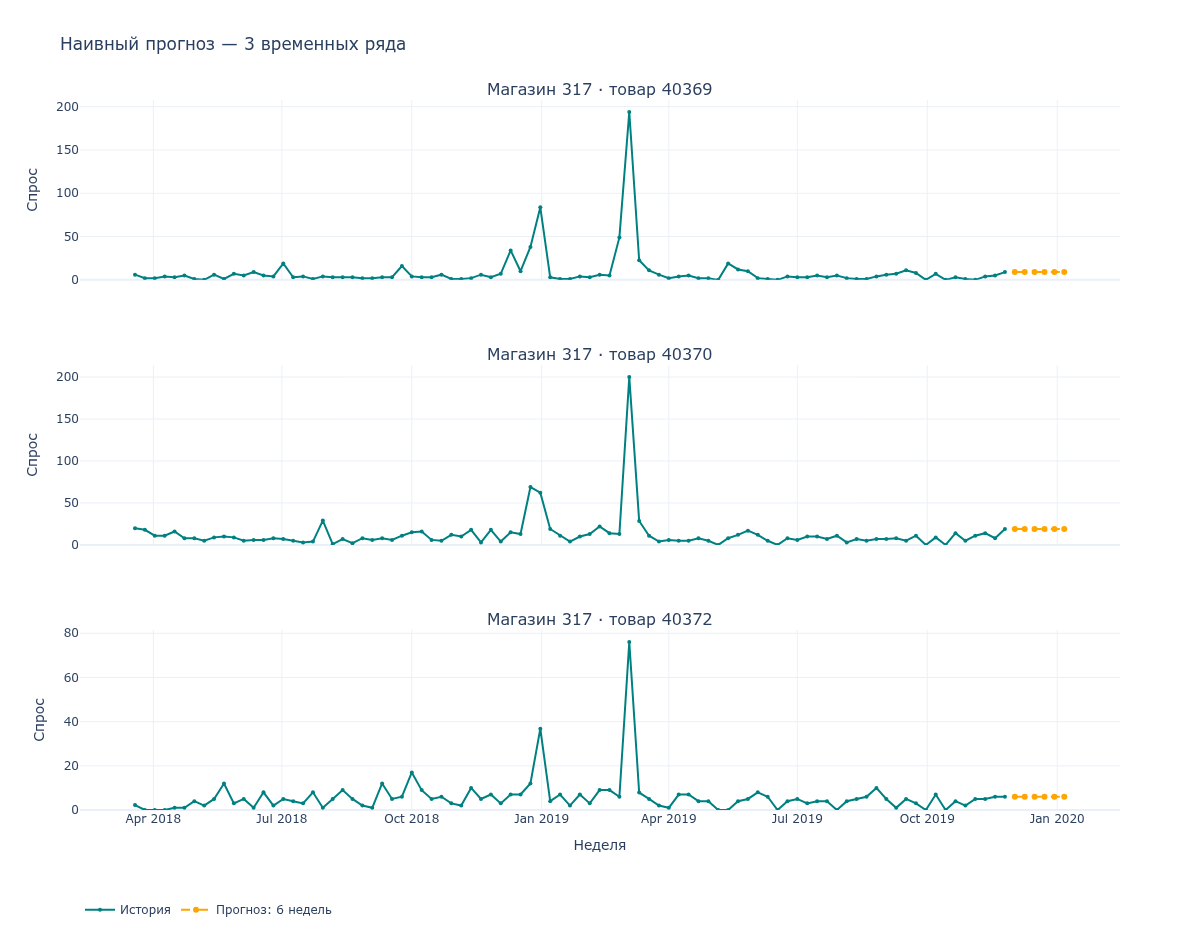

In [33]:
# Три примера реальной истории и наивного прогноза на будущие недели.
naive_examples = ts_retail.dropna(subset=['demand']).groupby(ts_id_columns)['demand'].count().sort_index().index[:3]
fig = make_subplots(rows=len(naive_examples), cols=1, shared_xaxes=True, vertical_spacing=0.12,
                    subplot_titles=[f'Магазин {store} · товар {product}' for store, product in naive_examples])
for row, (store, product) in enumerate(naive_examples, start=1):
    history = get_ts(ts_retail, product, store).dropna()
    future_dates = pd.date_range(history.index.max() + pd.Timedelta(weeks=1), periods=forecast_horizon, freq='7D')
    prediction = naive_forecast(history, forecast_horizon)
    shown_history = history.reindex(pd.date_range(history.index.min(), history.index.max(), freq='7D'))
    fig.add_trace(go.Scatter(x=shown_history.index, y=shown_history.values, mode='lines+markers', connectgaps=False,
                            name='История', legendgroup='history', showlegend=row == 1,
                            line=dict(color='teal'), marker=dict(size=4)), row=row, col=1)
    fig.add_trace(go.Scatter(x=future_dates, y=prediction, mode='lines+markers',
                            name=f'Прогноз: {forecast_horizon} недель', legendgroup='forecast', showlegend=row == 1,
                            line=dict(color='orange', dash='dash')), row=row, col=1)
    fig.update_yaxes(title_text='Спрос', rangemode='tozero', row=row, col=1)
fig.update_xaxes(title_text='Неделя', row=len(naive_examples), col=1)
fig.update_layout(title='Наивный прогноз — 3 временных ряда', height=940, width=1200,
                  legend=dict(orientation='h', y=-0.12, yanchor='top'), margin=dict(t=100, b=130))
fig.show()

Построение прогнозов для всех рядов на горизонт из test

Для каждой исторической даты строим прогноз на следующие `horizon` недель.
Первый факт для сравнения относится к неделе **после** даты прогноза.
Пропущенные календарные недели не сжимаем; неизвестные факты исключаем из WAPE.

In [34]:
def build_naive_forecasts_for_all(train_df, horizon=4):
    if not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("horizon должен быть положительным целым числом")
    columns = ['product_rk', 'store_location_rk', 'train_date', 'forecast_date',
               'forecast_date_idx', 'naive_forecast', 'actual_demand']
    results = []
    # В бэктесте используем только период с известным фактом, а не будущие строки Kaggle.
    observed = train_df.loc[train_df['demand'].notna()]
    for (product, store), group in observed.groupby(['product_rk', 'store_location_rk']):
        series = group.sort_values('period_start_dt').set_index('period_start_dt')['demand']
        series = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq='7D'))
        values = series.to_numpy(dtype=float)
        for i in range(len(series) - horizon):
            if not np.isfinite(values[i]):
                continue
            forecast = naive_forecast(values[:i + 1], horizon)
            for step in range(1, horizon + 1):
                results.append({
                    'product_rk': product,
                    'store_location_rk': store,
                    'train_date': series.index[i],
                    'forecast_date': series.index[i + step],
                    'forecast_date_idx': step,
                    'naive_forecast': forecast[step - 1],
                    'actual_demand': values[i + step],
                })
    forecasts_df = pd.DataFrame(results, columns=columns)
    print(f"Создано {len(forecasts_df)} прогнозов на горизонт {horizon} недель")
    return forecasts_df


### 2.2. Calculate WAPE metic for each 5-dim cell


**В данном разделе выполняется финальная сборка данных и расчет метрик качества прогнозирования:**

**Генерация признаков и прогнозов:**

Для всех временных рядов рассчитываются недостающие флаги: Seasonality, Trend и Intermittency.

Строится базовый Naive Forecast для проверки точности.

**Формирование 5-мерных ячеек:**

Данные объединяются в единую структуру, где каждый товар характеризуется 5 измерениями: Volume, Variability, Seasonality, Trend, Intermittency.

**Расчет WAPE с Bootstrapping:**

Для каждой уникальной комбинации признаков рассчитывается метрика WAPE.

Используется метод Bootstrapping для оценки доверительных интервалов 95%, что позволяет понять, насколько устойчива ошибка прогноза в данном сегменте.

In [35]:
print("Строим наивный прогноз")
forecasts_df = build_naive_forecasts_for_all(ts_retail, horizon=forecast_horizon)
if forecasts_df.empty:
    raise ValueError("Недостаточно истории для выбранного горизонта")

print("Объединяем рассчитанные признаки: сезонность, тренд, спорадичность (intermittency)")
inter_df = all_flags.copy()

flag_cols = ['has_seasonality', 'is_intermittent', 'has_trend']
ts_retail = ts_retail.drop(columns=flag_cols, errors='ignore')
for flags in [seas_df, inter_df, trend_df]:
    ts_retail = ts_retail.merge(flags, on=ts_id_columns, how='left', validate='many_to_one')
if ts_retail[flag_cols].isna().any().any():
    raise ValueError("Не для всех рядов рассчитаны признаки")
ts_retail[flag_cols] = ts_retail[flag_cols].astype(int)

Строим наивный прогноз


Создано 118086 прогнозов на горизонт 6 недель
Объединяем рассчитанные признаки: сезонность, тренд, спорадичность (intermittency)


In [36]:
segment_cols = ['volume_group', 'variability_group', 'has_seasonality', 'has_trend', 'is_intermittent']
features = ts_retail[ts_id_columns + segment_cols].drop_duplicates()
df_analysis = forecasts_df.merge(features, on=ts_id_columns, how='left', validate='many_to_one')
if df_analysis[segment_cols].isna().any().any():
    raise ValueError("Для части прогнозов не найдены сегменты")
print(f"Собрано {len(df_analysis)} записей для анализа.")

def calculate_bootstrap_wape(y_true, y_pred, n_bootstraps=100, random_state=42):
    y_t = np.asarray(y_true, dtype=float)
    y_p = np.asarray(y_pred, dtype=float)
    if y_t.shape != y_p.shape or y_t.ndim != 1:
        raise ValueError("Факт и прогноз должны быть одномерными массивами одинаковой длины")
    if n_bootstraps < 1:
        raise ValueError("n_bootstraps должен быть положительным")
    valid = np.isfinite(y_t) & np.isfinite(y_p)
    y_t, y_p = y_t[valid], y_p[valid]
    denominator = np.abs(y_t).sum()
    if denominator == 0:
        return np.nan, np.nan, np.nan
    # Точечная оценка — WAPE исходных наблюдений, а не среднее bootstrap-оценок.
    wape = np.abs(y_t - y_p).sum() / denominator
    if len(y_t) < 5:
        return wape, wape, wape
    rng = np.random.default_rng(random_state)
    scores = []
    for _ in range(n_bootstraps):
        indices = rng.integers(0, len(y_t), size=len(y_t))
        sample_denom = np.abs(y_t[indices]).sum()
        if sample_denom > 0:
            scores.append(np.abs(y_t[indices] - y_p[indices]).sum() / sample_denom)
    if not scores:
        return wape, np.nan, np.nan
    low, high = np.percentile(scores, [2.5, 97.5])
    return wape, low, high

results = []
for name, group in df_analysis.groupby(segment_cols, observed=True):
    valid_data = group.dropna(subset=['actual_demand', 'naive_forecast'])
    wape, low, high = calculate_bootstrap_wape(
        valid_data['actual_demand'], valid_data['naive_forecast'], random_state=RANDOM_SEED,
    )
    if not np.isfinite(wape):
        continue
    # Один и тот же факт встречается в нескольких окнах бэктеста.
    # Для доли продаж считаем его один раз, для ошибки учитываем все горизонты.
    unique_actuals = valid_data.drop_duplicates(ts_id_columns + ['forecast_date'])
    row = dict(zip(segment_cols, name))
    row.update({
        'WAPE': wape, 'WAPE_lower': low, 'WAPE_upper': high,
        'n_series': len(valid_data[ts_id_columns].drop_duplicates()),
        'total_volume': unique_actuals['actual_demand'].sum(),
        'absolute_error': np.abs(valid_data['actual_demand'] - valid_data['naive_forecast']).sum(),
        'actual_abs_sum': valid_data['actual_demand'].abs().sum(),
    })
    results.append(row)
fi_table = pd.DataFrame(results)
if fi_table.empty:
    raise ValueError("Нет сегментов с определённой WAPE")

Собрано 118086 записей для анализа.


### 2.3. Order all 5-dim cells on WAPE metric

**В данном пункте выполняется ранжирование и визуализация полученных результатов:**

**Сортировка:** Все 5-мерные сегменты упорядочиваются по возрастанию ошибки WAPE.

В начале списка оказываются самые «легкие» для прогнозирования сегменты.

В конце списка — самые «сложные».

**Forecastability Index Plot:** Строится график, который показывает кривую роста ошибки.

Ось X: Ранг сегмента (от простого к сложному).

Ось Y: Значение WAPE (ошибка прогноза).

**Тень (Confidence Interval):** Показывает 95% доверительный интервал ошибки, рассчитанный методом бутстрэпа (позволяет оценить устойчивость прогноза).

График позволяет визуально определить долю ассортимента, которая поддается прогнозированию с приемлемой точностью (например, WAPE < 40%), и выявить проблемные зоны.

Построение графика Forecastability Index
Проверка данных для графика:
  volume_group variability_group  has_seasonality  has_trend  is_intermittent  \
0            A                 C                1          1                0   
1            A                 C                1          0                1   
2            A                 C                1          1                1   
3            B                 C                1          0                0   
4            A                 C                0          1                1   

       WAPE  WAPE_lower  WAPE_upper  n_series  total_volume  absolute_error  \
0  0.611261    0.584345    0.648030         3   4500.585628    15711.427529   
1  0.620316    0.589404    0.651559         7  14294.813753    50817.183820   
2  0.667350    0.619024    0.707351         2   2330.056234     8730.570870   
3  0.674024    0.630318    0.719977         1    630.782352     2422.237252   
4  0.692512    0.667559    0.725206         5   

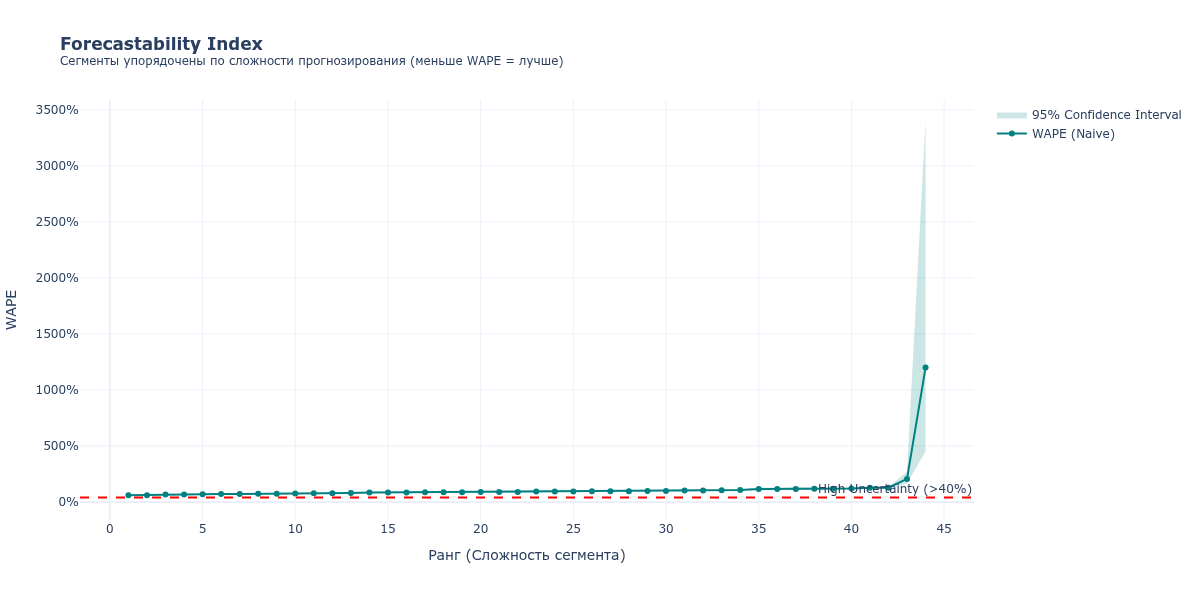


Топ-5 самых легко прогнозируемых сегментов:


,volume_group,variability_group,has_seasonality,WAPE,n_series
0,A,C,1,0.611261,3
1,A,C,1,0.620316,7
2,A,C,1,0.667350,2
3,B,C,1,0.674024,1
4,A,C,0,0.692512,5



Топ-5 самых сложных сегментов:


,volume_group,variability_group,has_seasonality,WAPE,n_series
39,B,A,1,1.202876,3
40,C,A,0,1.279197,6
41,C,A,1,1.287198,2
42,C,A,1,2.068571,6
43,C,A,1,12.000000,1


In [37]:
# 2.3
print("Построение графика Forecastability Index")

if len(fi_table) > 0:
    # Сортируем от самого легкого к самому сложному по WAPE
    fi_sorted = fi_table.sort_values(by='WAPE').reset_index(drop=True)
    fi_sorted['Rank'] = fi_sorted.index + 1

    def create_label(row):
        return (f"Vol:<b>{row['volume_group']}</b> | Var:<b>{row['variability_group']}</b><br>"
                f"Seas:{row['has_seasonality']} | Trd:{row['has_trend']} | Int:{row['is_intermittent']}<br>"
                f"Count: {row['n_series']}")

    fi_sorted['Label'] = fi_sorted.apply(create_label, axis=1)

    fig = go.Figure()

    # Линия доверительного интервала
    fig.add_trace(go.Scatter(
        x=pd.concat([fi_sorted['Rank'], fi_sorted['Rank'][::-1]]),
        y=pd.concat([fi_sorted['WAPE_upper'], fi_sorted['WAPE_lower'][::-1]]),
        fill='toself',
        fillcolor='rgba(0, 128, 128, 0.2)',
        line=dict(color='rgba(255,255,255,0)'),
        hoverinfo="skip",
        name='95% Confidence Interval'
    ))

    # Основная линия WAPE
    fig.add_trace(go.Scatter(
        x=fi_sorted['Rank'],
        y=fi_sorted['WAPE'],
        mode='lines+markers',
        name='WAPE (Naive)',
        line=dict(color='teal', width=2),
        text=fi_sorted['Label'],
        hovertemplate='<b>Rank: %{x}</b><br>WAPE: %{y:.1%}<br>%{text}<extra></extra>'
    ))

    # Линия отсечения
    fig.add_hline(y=0.4, line_dash="dash", line_color="red", annotation_text="High Uncertainty (>40%)")

    fig.update_layout(
        title='<b>Forecastability Index</b><br><sup>Сегменты упорядочены по сложности прогнозирования (меньше WAPE = лучше)</sup>',
        xaxis_title='Ранг (Сложность сегмента)',
        yaxis_title='WAPE',
        yaxis_tickformat='.0%',
        template='plotly_white',
        height=600,
        hovermode='closest'
    )

    print("Проверка данных для графика:")
    print(fi_sorted.head())
    print("WAPE min:", fi_sorted['WAPE'].min(), "WAPE max:", fi_sorted['WAPE'].max())


    fig.show()

    print("\nТоп-5 самых легко прогнозируемых сегментов:")
    display(fi_sorted[['volume_group', 'variability_group', 'has_seasonality', 'WAPE', 'n_series']].head(5))

    print("\nТоп-5 самых сложных сегментов:")
    display(fi_sorted[['volume_group', 'variability_group', 'has_seasonality', 'WAPE', 'n_series']].tail(5))

else:
    print("Таблица результатов пуста.")

Результаты следует интерпретировать по таблице и графику текущего запуска:
диапазон WAPE меняется при исправлении фильтра магазинов, горизонта и сдвига факта.
Высокая ошибка наивного прогноза сама по себе не доказывает, что ряд невозможно прогнозировать.

**Ограничения оценки:** признаки сегментов рассчитаны по всей доступной истории.
Это ретроспективное описание рядов, а не независимая проверка будущего качества сегментации.
Интервалы построены обычным bootstrap строк: перекрывающиеся окна зависимы,
поэтому номинальное покрытие 95% не гарантировано. Для строгой оценки нужны
признаки на каждом обучающем окне и временной либо кластерный bootstrap.

## 3. Aggregate 5-dim cells to clusters with similar forecastability

Объединяем 5-мерные сегменты по WAPE: Easy — ниже 50%, Medium — от 50% до 75%,
Hard — от 75%. Это заданные пороги, не ABC-анализ из первоначального задания.
WAPE кластера рассчитывается как отношение сумм абсолютной ошибки и спроса.
Доля объёма основана на уникальных фактах продаж, без повторов из окон бэктеста.

,Forecast_Cluster,n_series,total_volume,WAPE,Volume_Share
0,Easy (WAPE < 50%),0,0,nan%,0.0%
1,Medium (50% ≤ WAPE < 75%),27,"40,636",66.7%,20.5%
2,Hard (WAPE ≥ 75%),201,"157,664",97.3%,79.5%


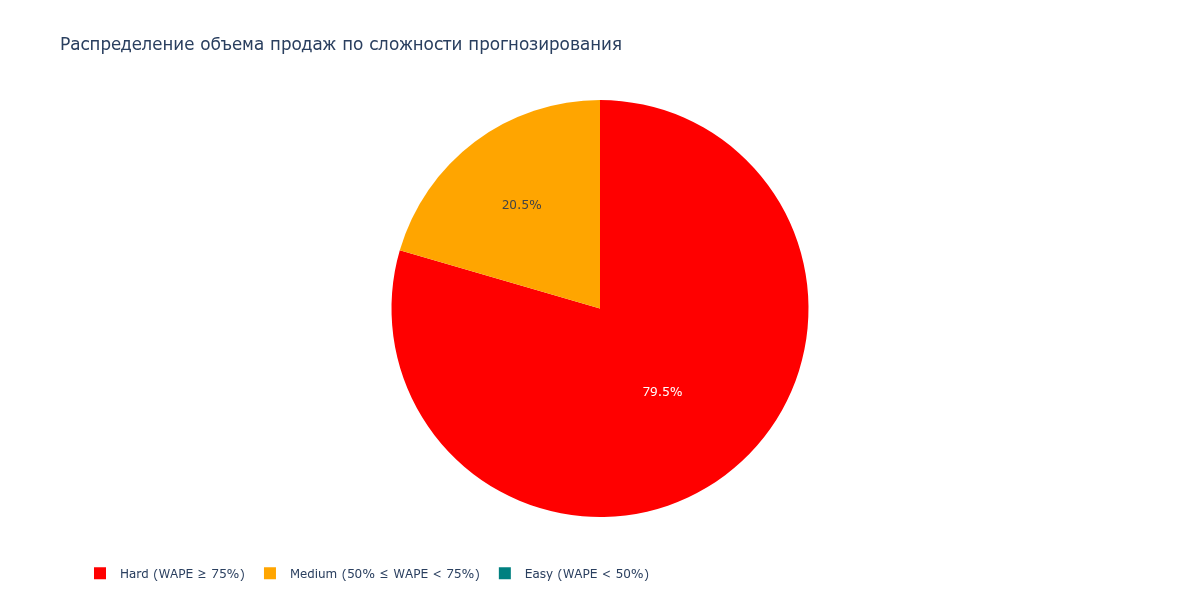

Рассчитано 44 сегментов для 228 рядов.
WAPE: 61.1% — 1200.0%
Все итоговые проверки пройдены; таблицы сохранены в outputs/.
Показано 45 примеров реальных рядов по типам; список сохранён в outputs/time_series_examples.csv.


In [38]:
bins = [0, 0.5, 0.75, np.inf]
labels = ['Easy (WAPE < 50%)', 'Medium (50% ≤ WAPE < 75%)', 'Hard (WAPE ≥ 75%)']
fi_cluster = fi_table.copy()
fi_cluster['Forecast_Cluster'] = pd.cut(
    fi_cluster['WAPE'], bins=bins, labels=labels, right=False, include_lowest=True,
)
cluster_stats = fi_cluster.groupby('Forecast_Cluster', observed=False).agg({
    'n_series': 'sum', 'total_volume': 'sum',
    'absolute_error': 'sum', 'actual_abs_sum': 'sum',
}).reset_index()
cluster_stats['WAPE'] = cluster_stats['absolute_error'] / cluster_stats['actual_abs_sum'].replace(0, np.nan)
cluster_stats['Volume_Share'] = cluster_stats['total_volume'] / cluster_stats['total_volume'].sum()

display(cluster_stats[['Forecast_Cluster', 'n_series', 'total_volume', 'WAPE', 'Volume_Share']].style.format({
    'WAPE': '{:.1%}', 'total_volume': '{:,.0f}', 'Volume_Share': '{:.1%}',
}))
fig = px.pie(
    cluster_stats, values='total_volume', names='Forecast_Cluster',
    title='Распределение объема продаж по сложности прогнозирования',
    color='Forecast_Cluster', color_discrete_map=dict(zip(labels, ['teal', 'orange', 'red'])),
)
fig.update_traces(textposition='inside', textinfo='percent', hovertemplate='%{label}<br>Объём: %{value:,.0f}<br>Доля: %{percent}<extra></extra>')
fig.update_layout(height=600, width=1200, legend=dict(orientation='h', y=-0.1))
fig.show()
# Отдельный интерактивный файл можно открыть в браузере без Jupyter и интернета.
fig.write_html(OUTPUT_DIR / 'forecastability_clusters.html', include_plotlyjs=True, full_html=True)

# Контроль итогов и выгрузка таблиц для проверки вне ноутбука.
assert (forecasts_df['forecast_date'] > forecasts_df['train_date']).all()
assert np.isfinite(fi_table['WAPE']).all()
assert fi_cluster['Forecast_Cluster'].notna().all()
assert np.isclose(cluster_stats['Volume_Share'].sum(), 1.0)
assert cluster_stats['n_series'].sum() == fi_table['n_series'].sum()
fi_table.to_csv(OUTPUT_DIR / 'forecastability_index.csv', index=False)
cluster_stats.to_csv(OUTPUT_DIR / 'forecastability_clusters.csv', index=False)
print(f"Рассчитано {len(fi_table)} сегментов для {fi_table['n_series'].sum()} рядов.")
print(f"WAPE: {fi_table['WAPE'].min():.1%} — {fi_table['WAPE'].max():.1%}")
print("Все итоговые проверки пройдены; таблицы сохранены в outputs/.")

examples_table = pd.DataFrame(series_example_records)
assert examples_table.groupby(['attribute', 'group']).size().between(2, 3).all()
examples_table.to_csv(OUTPUT_DIR / 'time_series_examples.csv', index=False)
print(f'Показано {len(examples_table)} примеров реальных рядов по типам; список сохранён в outputs/time_series_examples.csv.')